# Thiết kế (Design) – 10 bước đánh giá hiệu năng
## Mô phỏng asyncio các model queue của Node.js, Bun và Java Spring Loom

**Nhóm:** `<GroupName>`  **Thành viên:** `<tên – MSSV>`  **Hạn Phase 2:** 25/11/2026



**Hệ thống được mô hình hóa:** một request đi qua `Arrival → hàng đợi + trạm CPU → chờ I/O → Sink`. Sau khi xong CPU, request nhả ngay server CPU và chờ I/O ở trạm riêng (nhiều chỗ, M/M/∞), nên việc chờ I/O không chiếm CPU. Thread pool của Spring thường (thread giữ suốt CPU + I/O, tức blocking) chỉ được dùng làm **mốc so sánh**.

| Mục | Nội dung |
|---|---|
| §0 | Sample và vai trò (kèm phân tích số liệu thô) |
| §1–§7 | Bước 1–7 (chi tiết) |
| §8–§10 | Bước 8–10 (kế hoạch + mã hỗ trợ) |
| §11 | Mô tả module (kiến trúc, thành phần, luồng sự kiện) |
| §12 | Checklist và việc còn mở |

**Yêu cầu của thầy** tìm bài so sánh hiệu năng Node.js/Bun/Spring Loom **và** mô phỏng bằng asyncio các model queue của ba hệ thống; nộp sample chỉ cần link; Phase 2 nộp code và báo cáo (PDF + `.zip`), 25/11 chỉ cần xong source code mô phỏng.

In [1]:
import math, platform, sys, time
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Python", sys.version.split()[0], "|", platform.platform())

Python 3.12.3 | Linux-6.18.44-fc-v553-x86_64-with-glibc2.39


In [2]:
# Cấu hình đường dẫn tới framework BkitEvsim (thư mục chứa `bkitevsim/`).
import os, logging
CANDIDATES = [os.environ.get("BKITEVSIM_DIR", ""), "hk261_spe_BKsyspeEvsim", "../hk261_spe_BKsyspeEvsim"]
FRAMEWORK_DIR = next((p for p in CANDIDATES if p and os.path.isdir(os.path.join(p, "bkitevsim"))), None)
if FRAMEWORK_DIR is None:
    raise RuntimeError("Không thấy framework: giải nén hk261_spe_BKsyspeEvsim.zip cạnh notebook, "
                       "hoặc đặt biến môi trường BKITEVSIM_DIR trỏ tới thư mục chứa `bkitevsim/`.")
sys.path.insert(0, os.path.abspath(FRAMEWORK_DIR))
logging.disable(logging.CRITICAL)      # framework in cảnh báo "No events left" khi hết sự kiện; tắt cho gọn
print("Framework:", os.path.abspath(FRAMEWORK_DIR))

Framework: /home/claude/work/hk261_spe_BKsyspeEvsim


## 0. Sample và vai trò của nó

**Sample:** Repo GitHub: https://github.com/Frtrillo/spring-boot-virtual-threads-off-vs-on-vs-nodejs-typescript-benchmark
            Bài Medium (cùng tác giả): https://medium.com/@fr.trillo7/java-vs-node-js-vs-bun-spring-boot-nestjs-9a84db4fe5aa
 Bộ benchmark so sánh Java (Spring Boot), Node.js và Bun bằng `wrk` (8 thread, 1.000–2.000 kết nối, 60 s) trên bốn nhóm workload: tính toán thuần, tính toán ở mức framework, logic nghiệp vụ nặng CPU, I/O nặng đa core.


| # | Vai trò | Dùng ở bước |
|---|---|---|
| 1 | Thực tế để hiểu (cách đo web server bằng `wrk`) | 1, 2, 7 |
| 2 | Đối tượng để đánh giá (audit theo 10 bước) | toàn bộ |
| 3 | Kịch bản tham chiếu (closed-loop, 1.500 kết nối, 60 s) | 7, 8 |
| 4 | Nguồn tham số, **có giới hạn** (xem §0.2) | 4 |
| 5 | Bài học thiết kế (những lỗi của bài thành yêu cầu cho nhóm) | 3, 8, 9 |

### 0.1 Số liệu README (workload CPU nặng và I/O nặng)

In [3]:
readme = pd.DataFrame([
    ["I/O nặng",       "Node.js Cluster",       87047,   35.0,    8],
    ["I/O nặng",       "Java Virtual Threads",    444, 1720.0,    8],
    ["I/O nặng",       "Bun Single",              248, 6050.0,    1],
    ["Logic CPU nặng", "Bun single thread",     25345,   58.90,   1],
    ["Logic CPU nặng", "Node.js Cluster",       14725,  104.46,   8],
    ["Logic CPU nặng", "Node.js Single",         6185,  237.93,   1],
    ["Logic CPU nặng", "Java truyền thống",      4497,    4.52, None],
    ["Logic CPU nặng", "Java Virtual Threads",   4161,    2.35, None],
], columns=["workload", "cấu hình", "RPS (README)", "latency_ms", "cores"])
readme["L = X·R"] = readme["RPS (README)"] * readme["latency_ms"] / 1000
readme.round(1)

,workload,cấu hình,RPS (README),latency_ms,cores,L = X·R
0,I/O nặng,Node.js Cluster,87047,35.0,8.0,3046.6
1,I/O nặng,Java Virtual Threads,444,1720.0,8.0,763.7
2,I/O nặng,Bun Single,248,6050.0,1.0,1500.4
3,Logic CPU nặng,Bun single thread,25345,58.9,1.0,1492.8
4,Logic CPU nặng,Node.js Cluster,14725,104.5,8.0,1538.2
5,Logic CPU nặng,Node.js Single,6185,237.9,1.0,1471.6
6,Logic CPU nặng,Java truyền thống,4497,4.5,NaN,20.3
7,Logic CPU nặng,Java Virtual Threads,4161,2.4,NaN,9.8


### 0.2 Kiểm tra file kết quả thô (đã mở trực tiếp ba file `wrk` của workload CPU nặng)

Cùng endpoint `/api/process-order`, 8 thread, 1.500 kết nối, 60 s. `Non-2xx or 3xx responses` là số response lỗi mà `wrk` đã đếm vào "Requests/sec".

In [4]:
raw = pd.DataFrame([
    # file,                              tổng request, response lỗi, lỗi kết nối, lỗi đọc, latency TB (ms), "RPS" wrk
    ["result_realistic_nodejs.txt (Node single)", 371443,  311202,    0,  948, 237.93,  6185.86],
    ["result_realistic_bun.txt (Bun single)",    1522341, 1461415,    0,    0,  58.90, 25345.36],
    ["result_realistic_java_vt.txt (Java VT)",    250184,  227046, 1376,  539,   2.35,  4161.39],
], columns=["file", "tổng request", "response lỗi", "lỗi kết nối", "lỗi đọc", "latency_ms", "RPS wrk"])

T, C = 60.0, 1500
raw["tỉ lệ lỗi (%)"]        = 100 * raw["response lỗi"] / raw["tổng request"]
raw["thành công"]            = raw["tổng request"] - raw["response lỗi"]
raw["thành công/giây"]       = raw["thành công"] / T
raw["RPS wrk (kiểm tra)"]    = raw["tổng request"] / T
raw["L = X·R (RPS wrk)"]     = raw["RPS wrk"] * raw["latency_ms"] / 1000
raw[["file", "tổng request", "response lỗi", "tỉ lệ lỗi (%)", "thành công/giây", "RPS wrk",
     "RPS wrk (kiểm tra)", "L = X·R (RPS wrk)"]].round(2)

,file,tổng request,response lỗi,tỉ lệ lỗi (%),thành công/giây,RPS wrk,RPS wrk (kiểm tra),L = X·R (RPS wrk)
0,result_realistic_nodejs.txt (Node single),371443,311202,83.78,1004.02,6185.86,6190.72,1471.80
1,result_realistic_bun.txt (Bun single),1522341,1461415,96.00,1015.43,25345.36,25372.35,1492.84
2,result_realistic_java_vt.txt (Java VT),250184,227046,90.75,385.63,4161.39,4169.73,9.78


**Kết luận từ số liệu thô (đã kiểm chứng trên ba file):**
- "RPS" công bố là tổng response mà `wrk` đếm, **kể cả response lỗi**: 84–96% ở ba dòng này.
- Thông lượng thật của request thành công chỉ khoảng 1.000/giây (Node, Bun) và 386/giây (Java VT), chứ không phải 6.185, 25.345 và 4.161.
- Số response thành công của Node single và Bun gần như bằng nhau, trong khi "RPS" công bố chênh 4 lần. Nguyên nhân chưa rõ **[giả thuyết: giới hạn chung của logic nghiệp vụ hoặc dữ liệu; cần đọc code server và script `post.lua`]**.
- Dòng Java VT có 1.376 lỗi kết nối trên 1.500 kết nối; định luật Little cho `X·R ≈ 10`, lệch xa mức 1.500 của hai dòng JavaScript.

**Chưa kiểm tra:** Node cluster, Java truyền thống và toàn bộ dòng I/O (87.047 và 444 RPS). Nhóm cần mở file `result_*.txt` tương ứng và làm cùng phép tính trước khi kết luận.

**Hệ quả cho nhóm:** số liệu của bài **chưa đủ tin cậy để lấy làm `μ`**; `μ` được đặt theo kịch bản và phân tích độ nhạy (§4, §5).

### 0.3 Giả thuyết về tỉ lệ lỗi của sample (dùng để thiết kế E2)

Tỉ lệ lỗi 84–96% là dấu hiệu quen thuộc của một **hệ có sức chứa hữu hạn bị quá tải kiểu closed-loop**: `wrk` giữ 1.500 kết nối và gửi request kế tiếp ngay khi nhận phản hồi, kể cả phản hồi lỗi. Khi sức chứa `K` của server nhỏ hơn số kết nối, request thừa bị từ chối gần như tức thì, vòng lặp "bị từ chối → gửi lại" tạo ra hàng loạt response lỗi và làm "RPS" phình lên. Trong mô hình, hiện tượng này là **request bị từ chối khi trạm CPU đầy** (`P_block`), không liên quan đến việc CPU bị giữ khi chờ I/O. **[Giả thuyết, kiểm chứng ở E2 §8.]**

### 0.4 Các vấn đề của sample và việc nhóm làm khác

In [5]:
issues = pd.DataFrame([
    ["Throughput gồm 84–96% response lỗi",            "Nghiêm trọng", "Tách thông lượng thành công / bị từ chối / timeout; P_block là metric chính"],
    ["Không có kiểm tra nhất quán (Little)",         "Cao",          "Kiểm tra X·R ≈ C cho mọi lần chạy closed-loop (tính cả chu kỳ lỗi)"],
    ["Java VT: 1.376 lỗi kết nối / 1.500 kết nối",   "Cao",          "Loại lần chạy có lỗi kết nối ngoài ý muốn; mô phỏng chỉ có từ chối do `K` quy định"],
    ["Không mô hình hóa giới hạn tài nguyên (K, pool)", "Cao",       "Đưa K và kích thước pool P thành tham số và factor"],
    ["Khác số core giữa các hệ thống (bảng I/O)",    "Trung bình",   "Cùng số core c trong mỗi thí nghiệm"],
    ["Chỉ một lần chạy, không khoảng tin cậy",        "Trung bình",   "Nhiều hạt giống, khoảng tin cậy 95%"],
    ["Không rõ wrk và server có tách core/máy",      "Trung bình",   "Trong mô phỏng, tải và server là các LP độc lập, không tranh tài nguyên"],
    ["Chỉ throughput và latency",                    "Trung bình",   "Thêm hiệu suất CPU, P_block, số request trong hệ thống, p95/p99"],
    ["Máy đo ghi không nhất quán giữa hai phiên bản repo", "Thấp",   "Ghi rõ mọi tham số của nhóm"],
    ["Bảng xếp hạng Pi (100 triệu vòng) sai thứ hạng", "Thấp",       "Kiểm tra bảng kết quả trước khi trình bày"],
], columns=["Vấn đề của sample", "Mức độ", "Nhóm làm khác thế nào"])
issues

,Vấn đề của sample,Mức độ,Nhóm làm khác thế nào
0,Throughput gồm 84–96% response lỗi,Nghiêm trọng,Tách thông lượng thành công / bị từ chối / timeout; P_block là metric chính
1,Không có kiểm tra nhất quán (Little),Cao,Kiểm tra X·R ≈ C cho mọi lần chạy closed-loop (tính cả chu kỳ lỗi)
2,Java VT: 1.376 lỗi kết nối / 1.500 kết nối,Cao,Loại lần chạy có lỗi kết nối ngoài ý muốn; mô phỏng chỉ có từ chối do `K` quy định
3,"Không mô hình hóa giới hạn tài nguyên (K, pool)",Cao,Đưa K và kích thước pool P thành tham số và factor
4,Khác số core giữa các hệ thống (bảng I/O),Trung bình,Cùng số core c trong mỗi thí nghiệm
5,"Chỉ một lần chạy, không khoảng tin cậy",Trung bình,"Nhiều hạt giống, khoảng tin cậy 95%"
6,Không rõ wrk và server có tách core/máy,Trung bình,"Trong mô phỏng, tải và server là các LP độc lập, không tranh tài nguyên"
7,Chỉ throughput và latency,Trung bình,"Thêm hiệu suất CPU, P_block, số request trong hệ thống, p95/p99"
8,Máy đo ghi không nhất quán giữa hai phiên bản repo,Thấp,Ghi rõ mọi tham số của nhóm
9,Bảng xếp hạng Pi (100 triệu vòng) sai thứ hạng,Thấp,Kiểm tra bảng kết quả trước khi trình bày


## 1. Bước 1 – Mục tiêu và ranh giới hệ thống

### 1.1 Mục tiêu

**Mục tiêu tổng quát:** đánh giá hiệu năng của ba cách xử lý bất đồng bộ (event loop trong Node.js và Bun, virtual thread trong Spring Loom) khi một web server phục vụ nhiều request cùng lúc, bằng **mô phỏng asyncio các model queue** trên BkitEvsim; so với mốc blocking (Spring thread thường, thread pool); xác định điểm nghẽn và mức tải mà hệ thống không còn đáp ứng được.

**Mục tiêu cụ thể**
- Mô phỏng quá trình request đến, xếp hàng, được CPU xử lý, chờ I/O rồi trả lời, với giới hạn sức chứa `K` ở trạm CPU.
- Mô phỏng ba hệ (Node.js, Bun, Spring Loom) dưới dạng hệ nonblocking, cùng mô hình thread pool làm mốc blocking.
- Quan sát thời gian phản hồi, số request trong hệ thống, hiệu suất CPU và xác suất bị từ chối `P_block`.
- Quan sát hiện tượng quá tải, hàng chờ dài, request bị từ chối ở **ít nhất ba mức tải** (nhẹ, gần bão hòa, quá tải).
- Đánh giá hiệu năng toàn hệ thống (thông lượng, tỉ lệ bị từ chối, thời gian phản hồi) và xác định điểm nghẽn.
- Phân tích mức ảnh hưởng của các yếu tố (tải `γ`, số core `c`, dung lượng `K`, độ trễ I/O `D`, thời gian CPU `s`) lên hiệu năng.
- Tái hiện **xu hướng** của sample (closed-loop 1.500 kết nối) trong mô hình đã được kiểm chứng.

### 1.2 Câu hỏi quan sát

1. Với cùng số core, hệ nào bão hòa trước khi tải tăng (Node, Bun hay Loom)?
2. Khi nào thread pool bão hòa còn event loop và Loom thì không (phụ thuộc `D`)?
3. Event loop một luồng bão hòa ở `1/s`; Loom bão hòa ở `c/s`. Mô phỏng có tái hiện đúng các trần này không?
4. Giới hạn `K` và số core `c` ảnh hưởng `P_block` và `R` thế nào? Mở rộng `K` làm giảm `P_block` thật hay chỉ làm `R` dài hơn?
5. Thời gian chờ I/O `D` có làm tăng `R` cộng thêm đúng bằng `D` ở hệ nonblocking không, và làm giảm thông lượng thế nào ở thread pool?
6. Mô phỏng closed-loop có tái hiện được tỉ lệ lỗi cao của sample không? Kết quả lệch nhiều nhất so với lý thuyết ở trạm nào và vì sao?

### 1.3 Ngưỡng tham chiếu (sẽ hiệu chỉnh khi chạy thử)

| Chỉ số | Ngưỡng | Ý nghĩa |
|---|---|---|
| `P_block,sys` | dưới 1% | hệ thống đủ tin cậy |
| `R` trung bình | dưới 100 ms (với `D` = 50 ms, nghĩa là chờ ở hàng CPU dưới 50 ms) | trải nghiệm chấp nhận được |
| `R` p99 | dưới 300 ms | độ trễ đuôi |
| `X` | `X ≥ 0,95·γ` | gần như mọi request đến đều được phục vụ |
| Chênh lệch mô phỏng và giải tích (node đơn) | dưới 5% | mô hình đúng |

### 1.4 Hệ thống và thông tin hỗ trợ

**Phạm vi:** từ lúc request đến server đến lúc phản hồi xong (hoặc bị từ chối). **Không xét:** mạng, TLS, database thật, nhiều node, garbage collection, thời gian khởi động runtime, retry của client (trừ closed-loop).

**Sơ đồ.**

Hệ `FREE` (nonblocking):

```
                    bị từ chối khi số request ở trạm CPU = K (P_block)
                                          │
 Source(γ) ─► [ Trạm CPU: hàng chờ + c server, sức chứa K ] ─► [ Trạm I/O: chờ D, vô hạn chỗ ] ─► Sink
                  server nhả ngay sau khi xong CPU ──────────►   (chờ I/O không chiếm CPU)
```

Hệ `HOLD` (blocking, mốc so sánh) – **tách rõ $c = 8$ core CPU và $P = 200$ thread**:

```
              bị từ chối khi tổng số request trong hệ = K (P_block)
                                    │
 Source(γ) ─► [ Cổng thread: P = 200 thread ] ─► [ Hàng chờ core ] ─► [ c = 8 core: CPU Exp(s) ] ─► [ I/O: Exp(D) ] ─► Sink
                (hết thread: xếp hàng chờ thread)   (xếp hàng giành core)   (nhả core ngay sau CPU)      (thread vẫn bị giữ)
                      ▲                                                                                      │
                      └───────────── thread chỉ được trả sau khi xong I/O, rồi cấp cho request đang chờ thread ◄┘
```

**Hai chính sách của server khi request xong CPU:**

| Chính sách | Khi request xong CPU | Mô hình hàng đợi | Ai dùng | Vai trò |
|---|---|---|---|---|
| `FREE` (**nonblocking**) | nhả server CPU ngay; chờ I/O ở trạm riêng, không giới hạn chỗ | CPU: M/M/c/K → I/O: M/M/∞ | Node.js, Bun (event loop, $c = 1$); Spring Loom (virtual thread, $c$ carrier thread) | **hệ chính** |
| `HOLD` (blocking) | nhả **core** ngay, nhưng **vẫn giữ thread** suốt thời gian chờ I/O. Quy trình: giành 1 trong $P$ thread → xếp hàng giành 1 trong $c$ core → chạy CPU `Exp(s)` → nhả core → chờ I/O `Exp(D)` khi còn giữ thread → trả thread | cổng thread M/G/P/K → trạm core M/M/c → I/O (trong thread đang giữ) | Spring thread thường, pool $P$ thread | **mốc so sánh** |

**Tách $c$ và $P$ trong `HOLD`.** $c$ và $P$ là hai tài nguyên khác nhau, không được gộp thành một "server":

| Tài nguyên | Ký hiệu | Giá trị | Bận khi nào | Hệ quả |
|---|---|---|---|---|
| core CPU | $c$ | 8 | chỉ khi request đang **chạy CPU** | giới hạn tốc độ xử lý: $c/s$ |
| thread | $P$ | 200 | từ lúc request được cấp thread đến hết **CPU + I/O** (kể cả lúc đang xếp hàng giành core) | giới hạn số request đang xử lý: $P/(s+D)$ |
| sức chứa hệ | $K$ | 400 | tổng request trong hệ (đang giữ thread + chờ thread) | request đến khi đủ $K$ thì bị từ chối |

Vì $P \gg c$, nhiều thread cùng xếp hàng giành $c$ core: thời gian giữ thread là $W_{\text{core}} + s + D$ chứ không chỉ $s + D$; $W_{\text{core}}$ chỉ nhỏ khi CPU ít tranh chấp.

**Hoạt động:** request đến theo quá trình Poisson (open-loop) hoặc do `C` kết nối sinh ra (closed-loop). Request đến khi trạm CPU đã đủ `K` request thì bị từ chối (không xếp hàng, không quay lại trong open-loop). Ngược lại request vào trạm CPU, chờ server rảnh, được xử lý trong `s` (trung bình), sau đó rời server và chờ I/O trong `D` (trung bình), rồi ra Sink. Với `HOLD`, request chỉ được vào xếp hàng giành core khi có thread; phải chờ thread nếu cả $P$ thread đang bận, và thread chỉ được trả sau khi xong I/O.

**Các node (đơn vị thời gian: giây; giá trị khởi điểm, sẽ hiệu chỉnh khi chạy thử):**

| Node | Thành phần | Mô hình | c | K | μ |
|---|---|---|---|---|---|
| CPU | Node.js  | M/M/1/K | 1 | 100 | 1000/s (s = 1 ms) |
| CPU | Bun  | M/M/1/K | 1 | 100 | 1000·κ/s (κ = 1, thử 1,5 và 2) |
| CPU | Spring Loom (carrier thread) | M/M/c/K | 8 | 800 | 1000/s mỗi core |
| Thread (`HOLD`) | Cổng thread pool Spring thường (mốc) | M/G/P/K | $P = 200$ thread | $K = 400$ (tổng request trong hệ) | $1/(W_{\text{core}}+s+D)$ mỗi thread; ≈ 19,6/s khi bỏ qua $W_{\text{core}}$ |
| CPU (`HOLD`) | $c = 8$ core dùng chung giữa các thread | M/M/c | $c = 8$ | ≤ $P$ (chỉ request đã có thread) | 1000/s mỗi core |
| I/O (`HOLD`) | chờ I/O khi **vẫn giữ thread** | M/M/∞ (bị chặn bởi $P$) | ∞ | – | 1/D = 20/s |
| I/O | Trạm chờ I/O (cả ba hệ `FREE`) | M/M/∞ | ∞ | ∞ | 1/D = 20/s |
| Sink | Thu request hoàn thành | – | – | – | – |

**Giả định:**
1. Thời gian CPU phân phối mũ (để so với công thức); chạy thêm bản xác định để đo độ nhạy. Thời gian I/O mũ với trung bình `D` (giải tích) và bản xác định (độ nhạy).
2. Trạm I/O của hệ `FREE` có số chỗ không giới hạn (hạ tầng backend không là nút cổ chai); giả định này là điều kiện để hệ nonblocking.
3. Bun có cùng cấu trúc với Node (một event loop); chỉ khác `s` qua hệ số `κ`. 
4. `wrk`/nguồn tải không tranh CPU với server (LP độc lập).
5. Thread pool dùng cùng phần cứng với Loom ($c = 8$ core) nhưng có $P = 200$ thread ($P \gg c$). Trong `HOLD`, request chiếm 1 trong $P$ thread, **xếp hàng giành 1 trong $c$ core** (FCFS, thời gian phục vụ `Exp(s)`), nhả core khi xong CPU rồi mới đi chờ trạm I/O (`Exp(D)`) khi vẫn giữ thread. Tranh chấp CPU giữa nhiều thread được mô hình hóa tường minh bằng hàng chờ core; chỉ bỏ qua chi phí context switch.
6. Request bị từ chối ở cửa không được tính vào thông lượng thành công, đếm riêng.
7. Mỗi request chỉ chạy CPU **một lần** trước khi chờ I/O, không quay lại chiếm CPU sau khi xong I/O (không mô hình hóa callback/xử lý kết quả sau I/O).

**Chú thích – Node.js Cluster và Spring Loom.** Cả hai dùng 8 core nhưng khác cấu trúc hàng đợi. **Node.js Cluster** chạy 8 process, mỗi process có một event loop (1 server) và **hàng chờ riêng**; tải được chia cho các process trước khi vào hàng, nên một request không thể sang process khác dù process đó đang rảnh ⇒ **$8 \times$ M/M/1/K** (mỗi hàng nhận $\gamma/8$). **Spring Loom** có 8 carrier thread cùng lấy việc từ **một hàng chờ chung** ⇒ **M/M/8/K**. Cùng tổng năng lực $8/s$ nhưng M/M/8/K gộp hàng chờ nên $W_q$ và $P_{\text{block}}$ thường thấp hơn $8 \times$ M/M/1/K. Bảng node ở trên dùng Node.js **một process** ($c = 1$) làm cấu hình cơ sở; Cluster là kịch bản mở rộng.

### 1.5 Mô hình hóa toán học

**Hàng đợi đơn (ký hiệu Kendall $A/S/c/K$).** $A$ = phân phối khoảng cách đến (M = mũ, tương đương Poisson), $S$ = phân phối thời gian phục vụ (M = mũ, trung bình $1/\mu$), $c$ = số server, $K$ = sức chứa (đang phục vụ + đang chờ; khách đến khi đủ $K$ thì bị từ chối; $K=\infty$ không giới hạn). Mặc định FCFS và nguồn vô hạn.

**Quá trình sinh tử.** Gọi $n$ là số request trong node. $n$ tăng 1 với tốc độ $\lambda$ (khi $n<K$), giảm 1 với tốc độ $\min(n,c)\,\mu$. Ở trạng thái dừng, với $a=\lambda/\mu$ và $\rho=\lambda/(c\mu)$, xác suất có $n$ request trong node là $\pi_n$:

$$\tilde p_n=\begin{cases}\dfrac{a^n}{n!}, & 0\le n\le c\\[2mm]\dfrac{a^c}{c!}\Big(\dfrac{a}{c}\Big)^{n-c}, & c<n\le K\end{cases}\qquad \pi_n=\frac{\tilde p_n}{\sum_{k=0}^{K}\tilde p_k}$$

Xác suất bị từ chối là $P_{\mathrm{block}}=\pi_K$ (PASTA: request Poisson thấy trạng thái trung bình theo thời gian).

Sáu mô hình của đề là trường hợp riêng, chỉ khác cặp $(c,K)$:

| Mô hình | $(c, K)$ | Trong đề tài | Điều kiện / công thức chính |
|---|---|---|---|
| M/M/1 | $(1,\infty)$ | trạm CPU của Node/Bun khi bỏ giới hạn $K$ | $\pi_n=(1-\rho)\rho^{n}$, $\rho<1$ |
| M/M/c | $(c,\infty)$ | trạm CPU của Loom khi bỏ giới hạn $K$ | Erlang C: $C_E(c,a)=\dfrac{\frac{a^c}{c!}\frac{1}{1-\rho}}{\sum_{k=0}^{c-1}\frac{a^k}{k!}+\frac{a^c}{c!}\frac{1}{1-\rho}}$, $\rho<1$ |
| M/M/∞ | $(\infty,\infty)$ | **trạm chờ I/O** | $\pi_n=e^{-a}\,\dfrac{a^{n}}{n!}$ |
| M/M/1/K | $(1,K)$ | **trạm CPU của Node/Bun** | $\pi_K=\dfrac{(1-\rho)\rho^{K}}{1-\rho^{K+1}}$ ($\rho\ne1$); $\pi_K=\dfrac{1}{K+1}$ ($\rho=1$) |
| M/M/c/K | $(c,K)$ | **trạm CPU của Loom**, hàng chờ thread pool | $\pi_K=\dfrac{\tilde p_K}{\sum_{k=0}^{K}\tilde p_k}$ |
| M/M/c/c | $(c,c)$ | giới hạn kết nối backend không có chỗ chờ (mở rộng, §7.4 S8) | Erlang B: $B(c,a)=\dfrac{a^{c}/c!}{\sum_{j=0}^{c}a^{j}/j!}$ |

**Định luật Little.** $L=\lambda_{\mathrm{eff}}W$ và $L_q=\lambda_{\mathrm{eff}}W_q$, với $\lambda_{\mathrm{eff}}=\lambda(1-\pi_K)$ là tốc độ request thực sự được nhận. Đúng cho mọi kiểu hàng đợi nên dùng để kiểm tra mô phỏng.

**Tandem nonblocking (CPU → I/O).** Trạm I/O là M/M/∞ nên không bao giờ làm trạm CPU chậm lại: hai trạm **tách rời** về thời gian. Khi đó các chỉ số trung bình tính chính xác từ hai công thức đơn:
- tốc độ vào trạm I/O: $\lambda_{\mathrm{eff}}=\lambda(1-\pi_K)$ (luồng ra của trạm CPU hữu hạn không còn Poisson, nhưng số request trung bình trong trạm M/M/∞ chỉ phụ thuộc $\lambda_{\mathrm{eff}}$ và $D$);
- $R=W_{\mathrm{CPU}}+D$, $\quad L_{\mathrm{IO}}=\lambda_{\mathrm{eff}}\,D$, $\quad L_{\mathrm{sys}}=L_{\mathrm{CPU}}+\lambda_{\mathrm{eff}}\,D$.

Vì tính chính xác này, công thức giải tích dùng để **kiểm chứng mô phỏng** (sai số chỉ do nhiễu lấy mẫu); các phân vị (p95, p99) của $R$ và hệ thread pool (`HOLD`, thời gian giữ thread không mũ) chỉ có xấp xỉ.

**Phương trình lưu lượng.** Đường đi tuyến tính: $\lambda_{\mathrm{CPU}}=\gamma$, $\ \lambda_{\mathrm{IO}}=\gamma\,(1-\pi_K)$. Không có vòng phản hồi trong open-loop; trong closed-loop $\gamma$ do $C$ kết nối quyết định ($\gamma\approx X_{\mathrm{ok}}+X_{\mathrm{err}}$, với $X_{\mathrm{err}}$ là tốc độ bị từ chối).

**Điểm nghẽn lý thuyết** (thông lượng tối đa $X_{\max}$):

$$X_{\max}^{\mathrm{FREE}}=\frac{c}{s}\qquad X_{\max}^{\mathrm{HOLD}}=\min\Big(\frac{c}{s},\ \frac{P}{s+D}\Big)$$

Hệ `FREE` chỉ phụ thuộc CPU; thread pool bị trần $P/(s+D)$ khi $D$ lớn hoặc $P$ nhỏ (cận trên, bỏ qua thời gian chờ core $W_{\mathrm{core}}$).


## 2. Bước 2 – Dịch vụ và kết quả

**Dịch vụ:** server nhận một request, xử lý CPU (trung bình `s = 1/μ`), chờ I/O (trung bình `D`, **không chiếm CPU** ở hệ `FREE`), rồi trả lời. Với `HOLD`, thread giữ suốt `s + D`.

| Kết quả của một request | Định nghĩa trong mô phỏng | Ghi nhận |
|---|---|---|
| Hoàn thành | đi hết Source → CPU → I/O → Sink | thông lượng, thời gian phản hồi |
| Bị từ chối | đến khi trạm CPU đã đủ `K` request | bộ đếm từ chối, `P_block` |
| Timeout (mở rộng) | thời gian phản hồi vượt ngưỡng | đếm riêng, không tính vào thông lượng thành công |
| Đang dở khi kết thúc mô phỏng | chưa xong lúc $T_{\mathrm{end}}$ | không đưa vào trung bình (right-censoring) |

Quy ước rút ra từ sample: **thông lượng chỉ tính request hoàn thành thành công**; request bị từ chối đếm riêng và báo cáo cùng `P_block`.

**Ba mốc thời gian của một lần chạy** (đều là thời gian mô phỏng, $T_{\mathrm{warm}} \le T_{\mathrm{stop}} \le T_{\mathrm{end}}$):

| Mốc | Ký hiệu | Định nghĩa |
|---|---|---|
| Hết khởi động | $T_{\mathrm{warm}}$ | bắt đầu ghi thống kê (sau 10% request đầu) |
| Dừng sinh request mới | $T_{\mathrm{stop}}$ | thời điểm đến của request cuối cùng (đủ $N_{\mathrm{req}}$); sau đó Source không sinh request mới (closed-loop: các kết nối ngừng gửi) |
| Kết thúc mô phỏng | $T_{\mathrm{end}}$ | hàng đợi sự kiện rỗng hoặc đạt `end_time`; request còn dở lúc này bị right-censoring |

Cửa sổ quan sát $T_{\mathrm{obs}}=T_{\mathrm{stop}}-T_{\mathrm{warm}}$ là mẫu số của mọi tốc độ ($X$, $\lambda_{\mathrm{eff}}$) và của các trung bình theo thời gian ($U$, $L$). Request đến trong $[T_{\mathrm{warm}},T_{\mathrm{stop}}]$ được theo dõi đến khi xong (có thể sau $T_{\mathrm{stop}}$, trước $T_{\mathrm{end}}$). Đoạn $(T_{\mathrm{stop}},T_{\mathrm{end}}]$ chỉ là giai đoạn xả hàng, **không** tính vào $T_{\mathrm{obs}}$ vì tải giảm dần làm thấp $X$.

**Kết quả thu được:** bảng chỉ số từng trạm và toàn hệ thống, đối chiếu mô phỏng với giải tích, biểu đồ chỉ số theo tải, điểm nghẽn và so sánh với thread pool.

## 3. Bước 3 – Metric

Chia thành bốn nhóm: chỉ số trạm CPU, chỉ số trạm I/O, chỉ số toàn hệ thống, chỉ số độ tin cậy của kết quả.

**Quy ước chung**
- Chỉ tính sau khởi động, trong cửa sổ quan sát $[T_{\mathrm{warm}},T_{\mathrm{stop}}]$ với $T_{\mathrm{obs}}=T_{\mathrm{stop}}-T_{\mathrm{warm}}$ (§2).
- Chỉ số theo trạm chỉ tính request được trạm nhận; request bị từ chối chỉ xuất hiện trong $P_{\mathrm{block}}$.
- Ký hiệu: $a=\lambda/\mu$, $\rho=\lambda/(c\mu)$; $\pi_n$ là xác suất trạng thái dừng (§1.5).

### 3.1 Trạm CPU

| Metric | Ký hiệu | Công thức đo (mô phỏng) | Công thức lý thuyết | Ý nghĩa |
|---|---|---|---|---|
| Tốc độ vào hiệu dụng | $\lambda_{\mathrm{eff}}$ | số request được nhận $/\,T_{\mathrm{obs}}$ | $\lambda(1-\pi_K)$ | đầu vào của Little và $U$; dùng $\lambda$ thay $\lambda_{\mathrm{eff}}$ là sai khi có từ chối |
| Hiệu suất CPU | $U$ | $\int(\text{server bận})\,dt\,/\,(c\,T_{\mathrm{obs}})$ | $\lambda_{\mathrm{eff}}/(c\mu)$ | nút nào cần theo dõi; không đủ để kết luận nút cổ chai khi $K$ hữu hạn |
| Số request trong trạm | $L_{\mathrm{CPU}}$ | trung bình theo thời gian của $N(t)$ | $\sum_{n}n\,\pi_n$ | mức đông đúc |
| Số request chờ | $L_q$ | như trên, chỉ đếm hàng chờ | $\sum_{n>c}(n-c)\,\pi_n$ | |
| Thời gian chờ | $W_q$ | trung bình (bắt đầu CPU − đến) | $L_q/\lambda_{\mathrm{eff}}$ | so với ngưỡng |
| Thời gian ở trạm CPU | $W_{\mathrm{CPU}}$ | trung bình (xong CPU − đến) | $L_{\mathrm{CPU}}/\lambda_{\mathrm{eff}}$ | gồm chờ + CPU |
| Độ lệch chuẩn, p95, p99 | – | từ mẫu đã sắp xếp | dạng đóng chỉ cho M/M/1 và M/M/c: $P(W_q>t)=C_E(c,a)\,e^{-(c\mu-\lambda)t}$ | trung bình che giấu độ trễ đuôi |
| Xác suất bị từ chối | $P_{\mathrm{block}}$ | số bị từ chối / số đến | $\pi_K$ | **metric chính** |

### 3.2 Trạm I/O

| Metric | Ký hiệu | Công thức đo | Công thức lý thuyết | Ý nghĩa |
|---|---|---|---|---|
| Số request đang chờ I/O | $L_{\mathrm{IO}}$ | trung bình theo thời gian | $\lambda_{\mathrm{eff}}\,D$ | số kết nối backend đồng thời cần có |
| Thời gian ở trạm I/O | $W_{\mathrm{IO}}$ | trung bình (Sink − xong CPU) | $D$ | kiểm tra trực tiếp trạm M/M/∞ |

### 3.3 Toàn hệ thống

| Metric | Ký hiệu | Công thức đo | Ý nghĩa |
|---|---|---|---|
| Thông lượng thành công | $X$ | request hoàn thành $/\,T_{\mathrm{obs}}$ | hiệu quả thực tế; luôn $X\le\gamma$ |
| Thời gian phản hồi | $R$ | trung bình (Sink − đến), báo cả p95/p99; lý thuyết $W_{\mathrm{CPU}}+D$ | trải nghiệm người dùng |
| Xác suất bị từ chối toàn hệ thống | $P_{\mathrm{block,sys}}$ | bị từ chối / đến | độ tin cậy; so với ngưỡng 1% |
| Số request trong hệ thống | $L_{\mathrm{sys}}$ | trung bình $N_{\mathrm{CPU}}+N_{\mathrm{IO}}$ | $=X\,R$ theo Little |
| Hiệu suất sản xuất | $\eta=X/\gamma$ | thành công / đến | so với ngưỡng 95% |
| Điểm nghẽn và ngưỡng tải | $X_{\max}$ | $c/s$ (`FREE`); $\min\big(c/s,\ P/(s+D)\big)$ (`HOLD`) | trả lời "hệ nào bão hòa trước" |

Trong closed-loop thêm **tỉ lệ lỗi** = bị từ chối / (bị từ chối + thành công), để so với tỉ lệ lỗi 84–96% của sample.

### 3.4 Độ tin cậy của kết quả

Mỗi metric cho một giá trị $x_k$ ở mỗi lần chạy $k=1,\dots,m$ (mỗi lần một seed).
- **Khoảng tin cậy 95% (t-Student):** $\bar x \pm t_{0.975,\,m-1}\,\dfrac{\hat\sigma}{\sqrt m}$, với $\hat\sigma$ là độ lệch chuẩn mẫu của $x_1,\dots,x_m$. Các mẫu trong cùng một lần chạy tương quan nên **không** coi từng request là mẫu độc lập.
- **Sai số tương đối so với lý thuyết:** $\delta_{\mathrm{rel}}=\dfrac{|x_{\mathrm{sim}}-x_{\mathrm{theory}}|}{x_{\mathrm{theory}}}$; khớp khi khoảng tin cậy chứa giá trị lý thuyết. Với hệ `FREE` mọi chỉ số trung bình đều có nghiệm chính xác; với `HOLD` chỉ là xấp xỉ.
- **Kiểm tra Little:** $\dfrac{|L_{\mathrm{CPU}}-\lambda_{\mathrm{eff}}W_{\mathrm{CPU}}|}{L_{\mathrm{CPU}}}$ và $\dfrac{|L_{\mathrm{IO}}-\lambda_{\mathrm{eff}}D|}{L_{\mathrm{IO}}}$; toàn hệ thống $\dfrac{|L_{\mathrm{sys}}-XR|}{L_{\mathrm{sys}}}$; closed-loop kiểm tra $X_{\mathrm{ok}}R_{\mathrm{ok}}+X_{\mathrm{err}}R_{\mathrm{err}}\approx C$ (tính cả chu kỳ lỗi, §7.1).
- **Bảo toàn request:** $N_0+N_{\mathrm{arrived}}=N_{\mathrm{done}}+N_{\mathrm{rejected}}+N_{\mathrm{remaining}}$, với $N_0$ là số request đang có trong hệ lúc bắt đầu quan sát ($T_{\mathrm{warm}}$).

**Sample thiếu:** tỉ lệ lỗi, hiệu suất CPU, phân vị p95/p99, kiểm tra nhất quán. Nhóm bổ sung các phần này.


## 4. Bước 4 – Tham số

Tên tham số trong thiết kế (khớp tên tham số của `Dispatcher`/LP trong BkitEvsim):

| Tham số | Ý nghĩa | Công thức / giá trị |
|---|---|---|
| `mean_interarrival_time` | thời gian đến trung bình ở nguồn | `1/γ` |
| `mean_servicetime` | thời gian CPU trung bình của một server | `s = 1/μ` |
| `maxServer` | số server của trạm CPU | `c` |
| `maxSystemSize` | sức chứa trạm CPU | `K` |
| `mean_io_time` | thời gian I/O trung bình (trạm I/O vô hạn chỗ) | `D` |
| `policy` | chính sách nhả server | `FREE` / `HOLD` |
| `reject_time` | thời gian xử lý một phản hồi từ chối; closed-loop: kết nối chờ khoảng này trước khi gửi request kế tiếp | $t_{\mathrm{err}}>0$ (khởi điểm đề xuất $t_{\mathrm{err}}\ll s$, hiệu chỉnh khi chạy thử) |

Lưu ý: $t_{\mathrm{err}}$ phải **dương**. Nếu bằng 0, khi trạm đầy kết nối bị từ chối sẽ gửi lại ngay tại cùng thời điểm mô phỏng, tạo vòng lặp vô hạn không tiến thời gian và làm $X_{\mathrm{err}}R_{\mathrm{err}}=0$ trong kiểm tra Little. Open-loop không dùng tham số này.


In [6]:
params = pd.DataFrame([
    ["Mô phỏng", "Framework",                    "BkitEvsim, coroutine LP (asyncio)",         "chạy từ thư mục gốc framework"],
    ["Mô phỏng", "Phân phối đến",                "Poisson (open-loop) / C kết nối, think time z = 0 (closed-loop)", "γ = tốc độ đến"],
    ["Mô phỏng", "Phân phối phục vụ CPU",        "mũ (kiểm chứng giải tích) / xác định (độ nhạy)", "chạy cả hai và nêu sai khác"],
    ["Mô phỏng", "Phân phối thời gian I/O",      "mũ trung bình D (giải tích) / xác định D (độ nhạy)", ""],
    ["Mô phỏng", "Số request mỗi lần chạy",      "30.000 (BkitEvsim)", "bỏ 10% đầu (warm-up)"],
    ["Mô phỏng", "Số lần lặp m",                 "m = 10 hạt giống (đề xuất); 30 nếu đủ thời gian", "t(0,975; m−1) = 2,262 khi m = 10"],
    ["Mô phỏng", "bucket_width của LadderQueue", "chọn sao cho bucket_width × 1024 phủ thời gian mô phỏng", "mặc định của framework: 1,0 và 1024 bucket; `run_model` đặt `T_end/900` (§6.5)"],
    ["Mô phỏng", "Dispatcher",                   "sequential, distributed_sequential",          "kỳ vọng hai loại cho kết quả tương đương"],
    ["Kịch bản", "Thời gian CPU mỗi request s", "0,2 / 1 / 5 ms",                              "đặt theo kịch bản, không lấy từ sample"],
    ["Kịch bản", "Độ trễ I/O D",                "10 / 50 / 200 ms",                            ""],
    ["Kịch bản", "Số core / carrier thread c",  "1, 4, 8",                                     "Node/Bun: 1"],
    ["Kịch bản", "Dung lượng K = q·c (q: chỗ mỗi core)", "q = 10 / 100 / ∞",                       "K gồm đang chạy + hàng chờ"],
    ["Kịch bản", "Thời gian từ chối reject_time (t_err)", "t_err > 0 (đề xuất t_err ≪ s)",          "closed-loop: thời gian trước khi kết nối gửi lại sau khi bị từ chối; t_err = 0 gây vòng lặp vô hạn"],
    ["Kịch bản", "Số kết nối C (closed-loop)",   "100, 1.500, 5.000",                          "1.500 theo dạng tải của sample"],
    ["Kịch bản", "Kích thước thread pool P",    "200 (mốc so sánh)",                           "mặc định Tomcat cần xác nhận"],
    ["Kịch bản", "Hệ số tốc độ Bun κ",          "1 / 1,5 / 2",                                "giả thuyết: Bun nhanh hơn Node κ lần, không lấy từ sample"],
], columns=["Nhóm", "Tham số", "Giá trị", "Ghi chú"])
params

,Nhóm,Tham số,Giá trị,Ghi chú
0,Mô phỏng,Framework,"BkitEvsim, coroutine LP (asyncio)",chạy từ thư mục gốc framework
1,Mô phỏng,Phân phối đến,"Poisson (open-loop) / C kết nối, think time z = 0 (closed-loop)",γ = tốc độ đến
2,Mô phỏng,Phân phối phục vụ CPU,mũ (kiểm chứng giải tích) / xác định (độ nhạy),chạy cả hai và nêu sai khác
3,Mô phỏng,Phân phối thời gian I/O,mũ trung bình D (giải tích) / xác định D (độ nhạy),
4,Mô phỏng,Số request mỗi lần chạy,30.000 (BkitEvsim),bỏ 10% đầu (warm-up)
5,Mô phỏng,Số lần lặp R,10 hạt giống (đề xuất); 30 nếu đủ thời gian,"t(0,975; R−1) = 2,262 khi R = 10"
6,Mô phỏng,bucket_width của LadderQueue,chọn sao cho bucket_width × 1024 phủ thời gian mô phỏng,"mặc định của framework: 1,0 và 1024 bucket; `run_model` đặt `T_end/900` (§6.5)"
7,Mô phỏng,Dispatcher,"sequential, distributed_sequential",kỳ vọng hai loại cho kết quả tương đương
8,Kịch bản,Thời gian CPU mỗi request s,"0,2 / 1 / 5 ms","đặt theo kịch bản, không lấy từ sample"
9,Kịch bản,Độ trễ I/O D,10 / 50 / 200 ms,


**Phân loại hằng số, tham số, biến.**

| Loại | Nội dung |
|---|---|
| Hằng số | thời gian khởi động (10% số request đầu); số lần lặp $m$; phân phối CPU và I/O (mũ ở bản chính) |
| Tham số (đầu vào của một lần chạy) | `mean_interarrival_time = 1/γ`, `mean_servicetime = s`, `maxServer = c`, `maxSystemSize = K`, `mean_io_time = D`, `reject_time` $=t_{\mathrm{err}}$, seed |
| Biến yếu tố (đổi giữa kịch bản) | `γ` (trực tiếp; hoặc qua `ρ_ref` khi khảo sát nội bộ một hệ, §5), `c`, `K`, `D`, `s`, `policy`, `κ`, `C` |
| Biến trạng thái | `N_CPU(t)`, số server bận, $N_{\mathrm{IO}}(t)$, độ dài hàng chờ |
| Biến đầu ra | các metric ở §3 (ba chỉ số chính: `P_block,sys`, `R`, `X`) |



## 5. Bước 5 – Factor nghiên cứu

Mức in đậm là mức cơ sở.

In [7]:
factors = {
    "hệ thống":            ["**Node.js (c=1)**", "Bun (c=1, κ)", "**Spring Loom (c=8)**", "(mốc) Spring thread thường (pool P=200, HOLD)"],
    "mô hình tải":         ["**open-loop** (γ = ρ_ref · trần)", "closed-loop (C kết nối)"],
    "tải: ρ_ref (nội bộ 1 hệ) / γ tuyệt đối (so nhiều hệ)": ["0,3", "0,7", "**0,95**", "1,1"],
    "độ trễ I/O D":        ["10 ms", "**50 ms**", "200 ms"],
    "thời gian CPU s":     ["0,2 ms", "**1 ms**", "5 ms"],
    "số core c":           [1, 4, "**8**"],
    "dung lượng q = K/c": ["10", "**100**", "∞"],
}
pd.DataFrame([(k, len(v), ", ".join(map(str, v))) for k, v in factors.items()],
             columns=["Factor", "Số mức", "Các mức"])

,Factor,Số mức,Các mức
0,hệ thống,4,"**Node.js (c=1)**, Bun (c=1, κ), **Spring Loom (c=8)**, (mốc) Spring thread thường (pool P=200, HOLD)"
1,mô hình tải,2,"**open-loop** (γ = ρ_ref · trần), closed-loop (C kết nối)"
2,tải tương đối ρ_ref,4,"0,3, 0,7, **0,95**, 1,1"
3,độ trễ I/O D,3,"10 ms, **50 ms**, 200 ms"
4,thời gian CPU s,3,"0,2 ms, **1 ms**, 5 ms"
5,số core c,3,"1, 4, **8**"
6,dung lượng K / core,3,"10, **100**, ∞"


| Factor | Giả thuyết ảnh hưởng (kiểm chứng ở Phase 2) | Chỉ số phản hồi chính |
|---|---|---|
| hệ thống | cùng số core, chênh lệch chủ yếu do `μ`; thread pool khác ở chỗ giữ thread khi chờ I/O | `X`, `R`, `P_block` |
| tải `ρ_ref` | `P_block` và `R` tăng phi tuyến khi tiến gần trần | `P_block`, `R`, `X` |
| `D` | `R` tăng đúng `D` ở hệ `FREE`; `D` lớn làm thread pool bão hòa sớm (`P/(s+D)`) | `R`, `X` (pool) |
| `s` | `s` lớn làm CPU là nút cổ chai, event loop bão hòa ở `1/s` | `X`, `W_q` |
| `c` | event loop một luồng không tăng tốc theo core; Loom tăng theo `c/s` | `X`, `U` |
| `K` | `K` nhỏ làm `P_block` tăng khi tải gần bão hòa; `K` lớn kéo dài `R` | `P_block`, `R` |
| `κ` (Bun) | `κ` lớn dịch trần thông lượng của Bun lên `κ/s` | `X` |
| `C` (closed-loop) | `C > K` làm tỉ lệ lỗi cao như sample | tỉ lệ lỗi, `X·R` |

**Quy tắc chọn mức tải.**
- **Khảo sát nội bộ một hệ thống** (đổi $K$, $c$, $D$, $s$, ... trên cùng một hệ): dùng tải tương đối $\rho_{\mathrm{ref}}=\gamma/X_{\max}$, vì khi đó $X_{\max}$ cố định và $\rho_{\mathrm{ref}}$ chỉ là cách đặt lại thang tải.
- **So sánh nhiều hệ thống** (E1, E3: Node, Loom, Pool): **không** dùng $\rho_{\mathrm{ref}}$ chung, vì mỗi hệ có $X_{\max}$ khác nhau ($1/s$, $c/s$, $P/(s+D)$), nên cùng $\rho_{\mathrm{ref}}$ nghĩa là các hệ nhận tải khác nhau và so sánh bị lệch. Phải dùng **tải tuyệt đối $\gamma$ (req/s)** giống nhau cho mọi hệ.


## 6. Bước 6 – Kỹ thuật đánh giá

| Kỹ thuật | Nhận xét | Sử dụng |
|---|---|---|
| Mô hình giải tích | có công thức đóng cho từng node; cả tandem blocking chỉ gần đúng | **mốc đối chiếu** |
| Mô phỏng sự kiện rời rạc (DES) trên BkitEvsim (asyncio) | xử lý được blocking, hàng chờ hữu hạn, nhiều trạm; đổi tham số dễ; chạy lặp để có khoảng tin cậy | **kỹ thuật chính** (thuật toán §6.5, mã §6.6) |
| Đo đạc thực tế | không có hệ thống thật để đo; sample có số liệu nhưng chưa tin cậy (§0) | không dùng (tùy chọn: tự chạy `wrk` một lần cho mỗi runtime để đối chiếu độ lớn) |

### 6.1 Ánh xạ hệ thống sang hàng đợi

| Hệ thống | Trạm CPU | Trạm I/O | Chính sách |
|---|---|---|---|
| Node.js | M/M/1/K | M/M/∞ | `FREE` (nonblocking) |
| Bun (giả định) | M/M/1/K, μ·κ | M/M/∞ | `FREE` (nonblocking) |
| Spring + Loom (c carrier thread) | M/M/c/K | M/M/∞ | `FREE` (nonblocking) |
| (mốc) Spring thread thường (pool $P$ thread, $c$ core) | cổng thread M/G/P/K → trạm core M/M/c; thời gian giữ thread $W_{\text{core}}+s+D$ | I/O chờ khi còn giữ thread (không có trạm vô hạn chỗ riêng) | `HOLD` (blocking) |

Đủ sáu mô hình theo đề: M/M/1 và M/M/c (khi $K=\infty$), M/M/1/K (Node/Bun), M/M/c/K (Loom, pool), M/M/∞ (trạm I/O), M/M/c/c (giới hạn kết nối backend, kịch bản mở rộng S8).

### 6.2 Cài đặt công thức giải tích (cho node đơn)

Hàm bên dưới cài đặt các công thức của §1.5 (tóm tắt ở §6.3). Ký hiệu trong mã: `erlang_c` là $C_E(c,a)$, `erlang_b` là $B(c,a)$, `mmck` tính $\pi_n$ trong không gian log.

In [8]:
def mm1(lam, mu):
    rho = lam / mu
    if rho >= 1:
        return dict(rho=rho, stable=False, L=np.inf, W=np.inf, Wq=np.inf)
    W = 1 / (mu - lam)
    return dict(rho=rho, stable=True, L=rho / (1 - rho), W=W, Wq=W - 1 / mu)


def erlang_c(c, a):
    rho = a / c
    if rho >= 1:
        return 1.0
    s = sum(a**k / math.factorial(k) for k in range(c))
    top = a**c / math.factorial(c) / (1 - rho)
    return top / (s + top)


def mmc(lam, mu, c):
    a = lam / mu; rho = a / c
    if rho >= 1:
        return dict(rho=rho, stable=False, Pwait=1.0, L=np.inf, W=np.inf, Wq=np.inf)
    pw = erlang_c(c, a); Wq = pw / (c * mu - lam); W = Wq + 1 / mu
    return dict(rho=rho, stable=True, Pwait=pw, L=lam * W, W=W, Wq=Wq)


def mminf(lam, mu):
    return dict(L=lam / mu, W=1 / mu, Wq=0.0)


def mmck(lam, mu, c, K):
    """M/M/c/K (K>=c) tinh trong khong gian log de on dinh voi c, K lon."""
    a = lam / mu
    lp = []
    for n in range(K + 1):
        if n <= c:
            lp.append(n * math.log(a) - math.lgamma(n + 1) if a > 0 else (0.0 if n == 0 else -math.inf))
        else:
            lp.append(n * math.log(a) - math.lgamma(c + 1) - (n - c) * math.log(c))
    m = max(lp)
    p = [math.exp(x - m) for x in lp]
    Z = sum(p); p = [x / Z for x in p]
    pK = p[K]
    L = sum(n * p[n] for n in range(K + 1))
    Lq = sum((n - c) * p[n] for n in range(c + 1, K + 1))
    lam_eff = lam * (1 - pK)
    W = L / lam_eff if lam_eff > 0 else 0.0
    return dict(Pblock=pK, lam_eff=lam_eff, L=L, Lq=Lq, W=W, Wq=Lq / lam_eff if lam_eff > 0 else 0.0,
                U=lam_eff / (c * mu), P0=p[0])


def erlang_b(c, a):
    """Erlang B: B(c, a) cho M/M/c/c."""
    B = 1.0
    for k in range(1, c + 1):
        B = a * B / (k + a * B)
    return B


assert abs(mm1(8, 10)["W"] - 0.5) < 1e-12
assert abs(mmck(5, 10, 1, 1)["Pblock"] - 5 / 15) < 1e-12
assert abs(erlang_b(2, 1.0) - 0.2) < 1e-12
assert abs(mmck(30, 10, 5, 5)["Pblock"] - erlang_b(5, 3.0)) < 1e-12
print("Công thức qua kiểm tra cơ bản")

Công thức qua kiểm tra cơ bản


### 6.3 Tóm tắt công thức cài đặt trong mã

Với $a=\lambda/\mu$, $\rho=\lambda/(c\mu)$, $\lambda_{\mathrm{eff}}=\lambda(1-\pi_K)$ (chi tiết ở §1.5):

| Mô hình | Công thức |
|---|---|
| M/M/1 ($\rho<1$) | $W=\dfrac{1}{\mu-\lambda}$, $\ W_q=W-\dfrac1\mu$, $\ L=\dfrac{\rho}{1-\rho}$ |
| M/M/c ($\rho<1$) | $W_q=\dfrac{C_E(c,a)}{c\mu-\lambda}$, $\ W=W_q+\dfrac1\mu$, $\ L=\lambda W$ |
| M/M/∞ | $L=a$, $\ W=\dfrac1\mu$, $\ W_q=0$ |
| M/M/c/K (gồm M/M/1/K khi $c=1$) | $P_{\mathrm{block}}=\pi_K$, $\ L=\sum_{n=0}^{K}n\,\pi_n$, $\ L_q=\sum_{n=c+1}^{K}(n-c)\,\pi_n$, $\ W=\dfrac{L}{\lambda_{\mathrm{eff}}}$, $\ W_q=\dfrac{L_q}{\lambda_{\mathrm{eff}}}$, $\ U=\dfrac{\lambda_{\mathrm{eff}}}{c\mu}$ |
| M/M/c/c | $P_{\mathrm{block}}=B(c,a)=\dfrac{a^{c}/c!}{\sum_{j=0}^{c}a^{j}/j!}$; trùng M/M/c/K với $K=c$ (kiểm tra ở ô mã trên) |


### 6.4 Công thức giải tích cho tandem nonblocking

Trạm I/O là M/M/∞ không phản hồi lên trạm CPU nên, với $\lambda_{\mathrm{eff}}=\lambda(1-\pi_K)$:

$$R=W_{\mathrm{CPU}}+D,\qquad L_{\mathrm{IO}}=\lambda_{\mathrm{eff}}\,D,\qquad L_{\mathrm{sys}}=L_{\mathrm{CPU}}+\lambda_{\mathrm{eff}}\,D,\qquad X=\lambda_{\mathrm{eff}}$$

(§1.5). Các giá trị này là **chính xác** cho các chỉ số trung bình.


In [9]:
def tandem_free(lam, c, K, s, D):
    """Giai tich cho he nonblocking: tram CPU M/M/c/K -> tram I/O M/M/inf (khong phan hoi len CPU),
    nen cac chi so trung binh tinh chinh xac: R = W_A + D, L_B = lam_eff * D."""
    A = mmck(lam, 1.0 / s, c, K)
    return dict(Pblock=A["Pblock"], X=A["lam_eff"], W_A=A["W"], Wq=A["Wq"], R=A["W"] + D, L_A=A["L"],
                L_B=A["lam_eff"] * D, L_sys=A["L"] + A["lam_eff"] * D, U=A["U"])

### 6.5 Thuật toán mô phỏng

Phần này ghi trực tiếp thuật toán của mô hình ở §1.4, ở hai mức: **(A)** thuật toán hướng sự kiện lõi, độc lập framework; **(B)** cách chia thành các LP trên BkitEvsim (mã chạy được ở §6.6).

**Trạng thái và thống kê**
- `now`: thời gian mô phỏng; `n_cpu`: số request trong trạm CPU (đang chạy + đang chờ core); `busy`: số core bận; `Q`: hàng chờ core (FIFO); `n_io`: số request đang chờ I/O.
- Chỉ cho `HOLD`: `n_thr`: số thread đang bị giữ (≤ `P`); `QT`: hàng chờ thread (FIFO); `n_sys`: tổng request trong hệ (≤ `K`).
- Bộ đếm: `arrived`, `rejected`, `done` (chỉ đếm sau warm-up); danh sách `R[]` thời gian phản hồi.
- Tích phân theo thời gian (sau warm-up): `∫n_cpu dt`, `∫n_io dt`, `∫busy dt`.

**(A) Thuật toán lõi (hướng sự kiện)**

```
INPUT:  γ, c, K, s, D, t_err, policy ∈ {FREE, HOLD}, P (chỉ HOLD), T_warm, N_req, seed
INIT:   rng ← Random(seed);  now ← 0;  n_cpu ← busy ← n_io ← 0;  Q ← ∅
        n_sys ← n_thr ← 0;  QT ← ∅                      # chỉ dùng cho HOLD
        FEL ← hàng đợi ưu tiên theo timestamp (LadderQueue)
        FEL.push(ARRIVAL, Exp(γ))                       # closed-loop: đẩy C sự kiện ARRIVAL tại t = 0

WHILE FEL ≠ ∅:
    e ← FEL.pop_min();  Δ ← e.t − now;  now ← e.t
    cộng ∫n_cpu, ∫n_io, ∫busy phần của [now−Δ, now] nằm trong [T_warm, T_stop]

    CASE e.type OF
      ARRIVAL:
        IF đã sinh = N_req:  BỎ QUA                    # không sinh request mới sau T_stop
        đã sinh++;  T_stop ← now                       # T_stop = thời điểm đến của request thứ N_req
        open-loop: FEL.push(ARRIVAL, now + Exp(γ))
        req ← request mới (t_arr = now)
        IF policy = FREE:
            IF n_cpu = K:  TỪ_CHỐI(req)                # trạm CPU đầy: từ chối ở cửa
            ELSE:          VÀO_CPU(req)
        ELSE:                                          # HOLD: K tính trên tổng request trong hệ
            IF n_sys = K:  TỪ_CHỐI(req)
            ELSE:          n_sys++
                           IF n_thr < P:  n_thr++;  VÀO_CPU(req)    # có thread → xếp hàng giành core
                           ELSE:          QT.push(req)              # hết thread → chờ thread

      CPU_DONE(req):                                   # xong phục vụ CPU
        busy−−;  n_cpu−−                               # nhả core ngay (cả FREE và HOLD)
        n_io++;  FEL.push(IO_DONE(req), now + Exp(D))  # HOLD: request vẫn giữ thread khi chờ I/O
        IF Q ≠ ∅:  busy++;  BẮT_ĐẦU(Q.pop())

      IO_DONE(req):
        n_io−−;  GHI_PHẢN_HỒI(req)
        IF policy = HOLD:                              # trả thread
            n_sys−−
            IF QT ≠ ∅:  VÀO_CPU(QT.pop())              # thread chuyển cho request đang chờ
            ELSE:       n_thr−−

VÀO_CPU(req):    n_cpu++;  IF busy < c:  busy++;  BẮT_ĐẦU(req)   ELSE:  Q.push(req)
BẮT_ĐẦU(req):    FEL.push(CPU_DONE(req), now + Exp(s))
TỪ_CHỐI(req):    IF req.t_arr ≥ T_warm:  rejected++
                 closed-loop: FEL.push(ARRIVAL, now + t_err)               # t_err = reject_time > 0
GHI_PHẢN_HỒI(req): IF req.t_arr ≥ T_warm:  R.append(now − req.t_arr);  done++
                   closed-loop: FEL.push(ARRIVAL, now + z)                 # z = 0 (think time)

OUTPUT: P_block = rejected / arrived;  X = done / T_obs;  R̄, p95, p99 từ R[]
        L_cpu = ∫n_cpu / T_obs;  L_io = ∫n_io / T_obs;  U = ∫busy / (c·T_obs)
        với T_obs = T_stop − T_warm
```

**(B) Cài đặt trên BkitEvsim **

Mỗi thành phần là một lớp con của `BkSysCoLogicalProcess`. Theo mẫu của framework, **toàn bộ xử lý nằm trong `handle_event`** (kiểu PDES cổ điển); `coroutine_run` chỉ lên lịch sự kiện đầu tiên. LP gửi sự kiện bằng `send_event(Event(timestamp, sender_id, receiver_id, event_type, payload))`. Thời gian phục vụ CPU và độ trễ I/O được thể hiện bằng cách **gửi sự kiện cho chính mình với timestamp ở tương lai** (`SERVED`, `IO_FIN`), nên không cần `await advance_time` và không bị giới hạn một server mỗi LP chờ một lúc; mỗi server vẫn là một `WorkerLP` riêng (c server = c LP).

```
SourceLP:      coroutine_run:  gửi ARRIVAL (tới chính nó) tại Exp(γ)        # closed-loop: C ARRIVAL tại t = 0
               ON ARRIVAL:     nếu đã sinh < N_req:  gửi ARRIVAL kế tiếp tại now + Exp(γ);  gửi REQ{rid, t_arr} → DISP
               ON NEXT:        (closed-loop) sinh request kế tiếp ngay

DispatcherLP:  idle ← [0 … c−1];  Q ← ∅;  n ← 0                              # ghi lại (t, n, busy) mỗi lần đổi
               ON REQ:   nếu n = K:  gửi REJECT → SINK
                         ngược lại:  n++;  nếu idle ≠ ∅: gửi JOB → worker rảnh   ngược lại: Q.push
               ON IDLE{w}: n−−;  nếu Q ≠ ∅: gửi JOB(Q.pop) → worker w   ngược lại: idle.push(w)

WorkerLP[w]:   ON JOB:     gửi SERVED (tới chính nó) tại now + Exp(s)          # HOLD: now + Exp(s) + Exp(D)
               ON SERVED:  FREE: gửi IO_REQ → IO       HOLD: gửi DONE → SINK
                           gửi IDLE{w} → DISP                                  # nhả server ngay

IoLP (M/M/∞):  ON IO_REQ:  n_io++;  gửi IO_FIN (tới chính nó) tại now + Exp(D)   # không giới hạn số request đồng thời
               ON IO_FIN:  n_io−−;  gửi DONE → SINK

SinkLP:        ON DONE:    R.append(now − t_arr);  closed-loop: gửi NEXT → SRC tại now
               ON REJECT:  rejected++;             closed-loop: gửi NEXT → SRC tại now + t_err   # t_err = reject_time > 0
```

Với `HOLD`, `DispatcherLP` thêm `n_thr`, `QT` và tính `K` trên tổng request trong hệ; `WorkerLP` (= core) chỉ giữ cho phần CPU rồi luôn gửi `IO_REQ` và `IDLE`; `IoLP` gửi thêm `THREAD_FREE → DISP` khi xong I/O để trả thread.

**Thu thập thống kê, kết thúc, tái lập**
- **Warm-up:** bỏ mọi thống kê trước `T_warm` (10% request đầu); các tích phân chỉ cộng từ `T_warm`.
- **Kết thúc:** Source dừng sinh request mới tại $T_{stop}$ (đủ `N_req`); mô phỏng kết thúc tại $T_{end}$ khi hàng đợi sự kiện rỗng hoặc `now ≥ end_time`; request còn dở lúc kết thúc không đưa vào trung bình (right-censoring). `T_obs = T_stop − T_warm` (không tính đoạn xả hàng sau `T_stop`) để tránh đuôi xả hàng làm thấp `X`.
- **Tái lập:** mỗi LP dùng bộ sinh số ngẫu nhiên riêng với seed `base_seed + lp_id`; cùng seed thì kết quả giống hệt.
- **Chi phí:** thuật toán lõi (A) sinh khoảng **3 sự kiện mỗi request** (`ARRIVAL`, `CPU_DONE`, `IO_DONE`). Bản cài đặt tách LP trên BkitEvsim (B) sinh khoảng **8 sự kiện mỗi request** (`ARRIVAL`, `REQ`, `JOB`, `SERVED`, `IO_REQ`, `IDLE`, `IO_FIN`, `DONE`), vì mỗi bước đi qua một LP khác phải gửi sự kiện riêng; `HOLD` thêm 1 sự kiện `THREAD_FREE`. Request bị từ chối chỉ sinh khoảng 3 sự kiện (`ARRIVAL`, `REQ`, `REJECT`). Tổng chi phí tỉ lệ với `N_req` (mỗi thao tác hàng đợi ưu tiên khoảng O(1) với LadderQueue).

**Lưu ý khi cài đặt**
- Tham số `timeout` của `wait_for`/`wait_for_multiple` tính theo **giây đồng hồ thật**, trái với yêu cầu tách thời gian mô phỏng khỏi thời gian thực. Mã ở §6.6 không dùng `wait_for`; mọi độ trễ là sự kiện có timestamp mô phỏng. Timeout của request (kịch bản mở rộng) mô hình bằng sự kiện `TIMEOUT` tại `now + τ`.
- Không dựa vào thứ tự xử lý của các sự kiện có **cùng timestamp** (ví dụ `REQ` và `IDLE` đến cùng lúc). Kiểm tra: hai dispatcher `sequential` và `distributed_sequential` cho kết quả giống hệt nhau với cùng seed (§6.8).
- `bucket_width × 1024` phải phủ thời gian mô phỏng (vòng đệm 1024 bucket của LadderQueue); hàm `run_model` đặt `bucket_width = T_end / 900`.
- Framework **không có sẵn thống kê hàng đợi**; mã ghi lại `(t, n_cpu, busy)` và `(t, n_io)` mỗi lần đổi trạng thái rồi tính trung bình theo thời gian sau mô phỏng.
- `end_time` phải lớn hơn thời điểm request cuối xong; `run_model` đặt `T_end = 3·N_req/γ + 50(s+D)` (closed-loop dùng `3·N_req`).

### 6.6 Mã mô hình trên BkitEvsim

Mô hình gồm `SourceLP`, `DispatcherLP`, `WorkerLP × c`, `IoLP`, `SinkLP`. Hàm `run_model(γ, c, K, s, D, policy)` dựng `Simulation`, tạo LP, chạy và tính các chỉ số (sau warm-up 10%): `P_block`, `X`, `R`, p95, p99, `L_cpu`, `U`, $L_{\mathrm{IO}}$. `policy="FREE"` là hệ nonblocking; `policy="HOLD"` là thread pool (và với `D = 0` thành một trạm M/M/c/K để kiểm chứng node đơn).

In [10]:
import random
from collections import deque
from bkitevsim.core import Event, BkSysLogicalProcessState, Simulation, SimulationOptions
from bkitevsim.core.logical_coProcess import BkSysCoLogicalProcess

SRC, DISP, IO, SINK, W0 = 0, 1, 2, 3, 10          # lp_id cua Source, Dispatcher, Io, Sink; worker k co id W0 + k


class _Base(BkSysCoLogicalProcess):
    def __init__(self, lp_id, seed=1, **kw):
        super().__init__(lp_id, BkSysLogicalProcessState(), lookahead=0.0)
        self.rng = random.Random(seed * 1000 + lp_id)

    def _send(self, now, dst, etype, payload=None, at=None):
        self.send_event(Event(timestamp=now if at is None else at, sender_id=self.lp_id, receiver_id=dst,
                              event_type=etype, payload=payload or {}))

    async def coroutine_run(self):                  # moi viec xu ly nam o handle_event
        return


class SourceLP(_Base):
    def __init__(self, lp_id, seed=1, gamma=1.0, n_req=1000, closed_C=0, **kw):
        super().__init__(lp_id, seed)
        self.gamma, self.n_req, self.C = gamma, n_req, closed_C
        self.sent = 0; self.t_last = 0.0

    async def coroutine_run(self):
        if self.C:                                  # closed-loop: C ket noi gui request tai t = 0
            for _ in range(self.C): self._send(0.0, self.lp_id, "ARRIVAL", {}, at=0.0)
        else:                                       # open-loop: Poisson(gamma)
            self._send(0.0, self.lp_id, "ARRIVAL", {}, at=self.rng.expovariate(self.gamma))

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "ARRIVAL" or e.event_type == "NEXT":
            if self.sent >= self.n_req: return
            self.sent += 1; self.t_last = t
            if not self.C and e.event_type == "ARRIVAL":
                self._send(t, self.lp_id, "ARRIVAL", {}, at=t + self.rng.expovariate(self.gamma))
            self._send(t, DISP, "REQ", {"rid": self.sent, "t_arr": t})


class DispatcherLP(_Base):
    def __init__(self, lp_id, seed=1, c=1, K=10**9, **kw):
        super().__init__(lp_id, seed)
        self.K, self.idle, self.Q, self.n = K, list(range(c)), deque(), 0
        self.c = c; self.trace = [(0.0, 0, 0)]     # (t, n_cpu, busy)

    def _log(self, t): self.trace.append((t, self.n, self.c - len(self.idle)))

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "REQ":
            if self.n >= self.K:
                self._send(t, SINK, "REJECT", e.payload)
            else:
                self.n += 1
                if self.idle: self._send(t, W0 + self.idle.pop(), "JOB", e.payload)
                else: self.Q.append(e.payload)
                self._log(t)
        elif e.event_type == "IDLE":
            self.n -= 1; w = e.payload["w"]
            if self.Q: self._send(t, W0 + w, "JOB", self.Q.popleft())
            else: self.idle.append(w)
            self._log(t)


class WorkerLP(_Base):
    def __init__(self, lp_id, seed=1, s=1e-3, D=0.0, policy="FREE", **kw):
        super().__init__(lp_id, seed)
        self.s, self.D, self.policy = s, D, policy

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "JOB":
            dur = self.rng.expovariate(1 / self.s)
            if self.policy == "HOLD" and self.D > 0: dur += self.rng.expovariate(1 / self.D)
            self._send(t, self.lp_id, "SERVED", e.payload, at=t + dur)
        elif e.event_type == "SERVED":
            if self.policy == "FREE": self._send(t, IO, "IO_REQ", e.payload)
            else: self._send(t, SINK, "DONE", e.payload)
            self._send(t, DISP, "IDLE", {"w": self.lp_id - W0})


class IoLP(_Base):                                   # M/M/inf: khong gioi han so request dong thoi
    def __init__(self, lp_id, seed=1, D=0.05, **kw):
        super().__init__(lp_id, seed)
        self.D = D; self.n = 0; self.trace = [(0.0, 0)]

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "IO_REQ":
            self.n += 1; self.trace.append((t, self.n))
            self._send(t, self.lp_id, "IO_FIN", e.payload, at=t + self.rng.expovariate(1 / self.D))
        elif e.event_type == "IO_FIN":
            self.n -= 1; self.trace.append((t, self.n))
            self._send(t, SINK, "DONE", e.payload)


class SinkLP(_Base):
    def __init__(self, lp_id, seed=1, closed=False, **kw):
        super().__init__(lp_id, seed)
        self.closed = closed; self.resp = []; self.rejected = []; self.done_t = []

    def handle_event(self, e):
        t = e.timestamp
        if e.event_type == "DONE":
            self.resp.append((e.payload["t_arr"], t - e.payload["t_arr"])); self.done_t.append(t)
        elif e.event_type == "REJECT":
            self.rejected.append(e.payload["t_arr"])
        if self.closed: self._send(t, SRC, "NEXT", {})


MODELS = {"SourceLP": SourceLP, "DispatcherLP": DispatcherLP, "WorkerLP": WorkerLP, "IoLP": IoLP, "SinkLP": SinkLP}


import concurrent.futures


def _run_sim(sim):
    # Jupyter da co san event loop, con framework goi asyncio.run() nen phai chay sim.run() trong thread rieng.
    with concurrent.futures.ThreadPoolExecutor(max_workers=1) as ex:
        return ex.submit(sim.run).result()


def run_model(gamma, c, K, s, D, policy="FREE", n_req=20000, warm=0.1, seed=1, closed_C=0, dispatcher="sequential"):
    # Dung Simulation cua BkitEvsim, chay va tinh cac chi so sau warm-up.
    import numpy as np
    t_end = (n_req / gamma if not closed_C else n_req * 1.0) * 3 + 50 * (s + D)
    sim = Simulation(SimulationOptions(end_time=t_end, dispatcher=dispatcher, bucket_width=max(t_end / 900, 1e-3)),
                     models=MODELS)
    sim.create_lp(SRC, "SourceLP", seed=seed, gamma=gamma, n_req=n_req, closed_C=closed_C)
    sim.create_lp(DISP, "DispatcherLP", seed=seed, c=c, K=K)
    if policy == "FREE": sim.create_lp(IO, "IoLP", seed=seed, D=D)
    sim.create_lp(SINK, "SinkLP", seed=seed, closed=bool(closed_C))
    for k in range(c): sim.create_lp(W0 + k, "WorkerLP", seed=seed, s=s, D=D, policy=policy)
    stats = _run_sim(sim)
    src, disp, sink = sim.get_lp(SRC), sim.get_lp(DISP), sim.get_lp(SINK)
    io = sim.get_lp(IO) if policy == "FREE" else None
    t_warm = warm * src.t_last; t_stop = src.t_last; T = t_stop - t_warm
    def tavg(trace, col):                               # trung binh theo thoi gian tren [t_warm, t_stop]
        a = np.array(trace, dtype=float); t = a[:, 0]; v = a[:, col]
        t1 = np.minimum(np.append(t[1:], t_stop), t_stop); t0 = np.maximum(t, t_warm)
        return float(np.sum(v * np.clip(t1 - t0, 0, None)) / T)
    resp = np.array([r for ta, r in sink.resp if ta >= t_warm]); rej = [ta for ta in sink.rejected if ta >= t_warm]
    n_obs = len(resp) + len(rej)
    return dict(Pblock=len(rej) / n_obs, X=len(resp) / T, R=float(resp.mean()), p95=float(np.percentile(resp, 95)),
                p99=float(np.percentile(resp, 99)), L_cpu=tavg(disp.trace, 1), U=tavg(disp.trace, 2) / c,
                L_io=tavg(io.trace, 1) if io else float("nan"), events=stats["events_processed"],
                wall=stats["wall_time"], n_done=len(resp), n_rej=len(rej))

### 6.7 Kiểm chứng từng node đơn trên framework

Mỗi mô hình hàng đợi được chạy bằng `run_model(..., policy="HOLD", D=0)` (một trạm M/M/c/K, `K` rất lớn nếu hàng chờ vô hạn) với 30.000 request, lặp 5 hạt giống và so với công thức ở §6.3 (khoảng tin cậy 95% theo phân phối t). M/M/∞ (trạm I/O) được kiểm chứng ở cột $L_{\mathrm{IO}}$ của §6.8.

In [11]:
BIG = 10**9
cases = [
    ("M/M/1",               7, 10, 1,  BIG, lambda: mm1(7, 10)["W"]),
    ("M/M/1/K (K=5)",       9, 10, 1,  5,   lambda: mmck(9, 10, 1, 5)["W"]),
    ("M/M/c (c=4)",        32, 10, 4,  BIG, lambda: mmc(32, 10, 4)["W"]),
    ("M/M/c/K (c=4,K=10)", 38, 10, 4,  10,  lambda: mmck(38, 10, 4, 10)["W"]),
    ("M/M/c/c (c=5)",      30, 10, 5,  5,   lambda: mmck(30, 10, 5, 5)["W"]),
]
rows = []
for name, lam, mu, c, K, f in cases:
    runs_ = [run_model(lam, c, K, 1 / mu, 0.0, "HOLD", n_req=30_000, seed=sd) for sd in range(1, 6)]     # 5 hạt giống
    w = np.array([r["R"] for r in runs_]); pb = np.mean([r["Pblock"] for r in runs_])
    h = stats.sem(w) * stats.t.ppf(0.975, len(w) - 1)
    W_th = f(); pb_th = mmck(lam, mu, c, K)["Pblock"] if K < BIG else 0.0
    rows.append([name, W_th * 1000, w.mean() * 1000, (w.mean() - h) * 1000, (w.mean() + h) * 1000,
                 100 * (w.mean() - W_th) / W_th, bool((w.mean() - h) <= W_th <= (w.mean() + h)), pb_th, pb])
verif = pd.DataFrame(rows, columns=["Mô hình", "W giải tích (ms)", "W BkitEvsim TB (ms)", "CI95 dưới", "CI95 trên",
                                    "Sai số W (%)", "CI chứa giá trị lý thuyết", "P_block giải tích", "P_block BkitEvsim"])
print("Sai số W lớn nhất (%):", round(float(verif["Sai số W (%)"].abs().max()), 2),
      "| giá trị lý thuyết nằm trong CI95 ở mọi mô hình:", bool(verif["CI chứa giá trị lý thuyết"].all()))
verif.round(4)

Sai số W lớn nhất (%): 2.48 | giá trị lý thuyết nằm trong CI95 ở mọi mô hình: True


,Mô hình,W giải tích (ms),W BkitEvsim TB (ms),CI95 dưới,CI95 trên,Sai số W (%),CI chứa giá trị lý thuyết,P_block giải tích,P_block BkitEvsim
0,M/M/1,333.3333,341.3360,324.9234,357.7486,2.4008,True,0.0000,0.0000
1,M/M/1/K (K=5),279.0286,281.5162,276.3074,286.7250,0.8915,True,0.1260,0.1287
2,M/M/c (c=4),174.5541,178.8835,166.1332,191.6338,2.4803,True,0.0000,0.0000
3,"M/M/c/K (c=4,K=10)",157.3815,157.8945,154.4632,161.3258,0.3260,True,0.0868,0.0892
4,M/M/n/n (n=5),100.0000,100.1344,99.1169,101.1518,0.1344,True,0.1101,0.1107


### 6.8 Kiểm chứng tandem nonblocking, hai dispatcher và tính tái lập

In [12]:
s, D = 1e-3, 50e-3
rows = []
for c, K, rho in [(1, 100, 0.7), (1, 100, 0.95), (1, 100, 1.1), (1, 10, 0.95), (8, 800, 0.95), (8, 800, 1.1)]:
    lam = rho * c / s
    th = tandem_free(lam, c, K, s, D)
    sm = run_model(lam, c, K, s, D, "FREE", n_req=30_000, seed=3)
    rows.append([f"c={c}, K={K}, ρ={rho}", th["Pblock"], sm["Pblock"], th["R"] * 1e3, sm["R"] * 1e3,
                 100 * (sm["R"] - th["R"]) / th["R"], th["L_B"], sm["L_io"], th["L_A"], sm["L_cpu"]])
chk = pd.DataFrame(rows, columns=["Cấu hình", "P_block th", "P_block sim", "R th (ms)", "R sim (ms)", "sai số R (%)",
                                  "L_I/O th", "L_I/O sim", "L_CPU th", "L_CPU sim"])
chk.round(4)

,Cấu hình,P_block th,P_block sim,R th (ms),R sim (ms),sai số R (%),L_I/O th,L_I/O sim,L_CPU th,L_CPU sim
0,"c=1, K=100, ρ=0.7",0.0000,0.0000,53.3333,53.5401,0.3876,35.0000,35.0507,2.3333,2.2933
1,"c=1, K=100, ρ=0.95",0.0003,0.0000,69.4044,69.2537,-0.2171,47.4859,47.6507,18.4287,18.0620
2,"c=1, K=100, ρ=1.1",0.0909,0.0866,140.0073,140.2662,0.1850,49.9997,50.4086,90.0067,90.1045
3,"c=1, K=10, ρ=0.95",0.0694,0.0670,55.0787,55.3191,0.4365,44.2022,44.4279,4.4898,4.4536
4,"c=8, K=800, ρ=0.95",0.0000,0.0000,53.1104,53.4213,0.5853,380.0000,380.9381,23.6392,24.0177
5,"c=8, K=800, ρ=1.1",0.0909,0.0844,148.7500,145.0741,-2.4712,400.0000,396.3532,790.0000,750.3772


## 7. Bước 7 – Workload

Workload trong mô phỏng là **chuỗi request đến server**, định nghĩa bởi mô hình tải, mức tải và kịch bản dịch vụ. Cấu hình hệ thống giữ nguyên trong một workload.

### 7.1 Mô hình tải
- **Open-loop:** tốc độ đến `γ` cố định (Poisson), không phụ thuộc phản hồi. Dùng để so với công thức M/M/· và đo độ trễ đuôi.
- **Closed-loop:** `C` kết nối đồng thời, mỗi kết nối gửi request kế tiếp ngay khi nhận phản hồi (think time `z = 0`), kể cả phản hồi bị từ chối. Đây là cách `wrk` của sample hoạt động. Kiểm tra Little cho closed-loop: $$X_{\mathrm{ok}}R_{\mathrm{ok}}+X_{\mathrm{err}}R_{\mathrm{err}}\approx C,\qquad R_{\mathrm{err}}=t_{\mathrm{err}}>0$$ (mỗi kết nối luôn ở trong một request thành công hoặc một chu kỳ bị từ chối). Vì $R_{\mathrm{err}}=t_{\mathrm{err}}>0$ nhưng nhỏ nên $X_{\mathrm{ok}}R_{\mathrm{ok}}=C-X_{\mathrm{err}}t_{\mathrm{err}}\le C$, dấu "bằng" chỉ khi $P_{\mathrm{block}}\approx0$ ($X_{\mathrm{err}}\approx0$).

### 7.2 Mức tải
Khi khảo sát nội bộ một hệ, mức tải được đặt theo **tải tương đối** $\rho_{\mathrm{ref}}=\gamma/X_{\max}$ của hệ đó ($X_{\max}$ ở §1.5). Khi **so sánh nhiều hệ** (E1, E3) phải dùng **tải tuyệt đối $\gamma$ (req/s)** chung (quy tắc ở §5); bảng dưới là mức $\rho_{\mathrm{ref}}$ cho trường hợp khảo sát nội bộ:

| Workload | `ρ_ref` | Mục đích |
|---|---|---|
| WL1 – nhẹ | 0,3 | chế độ nhẹ, kỳ vọng không từ chối |
| WL2 – cơ sở | 0,7 | vận hành thông thường |
| WL3 – gần bão hòa | 0,95 | tìm điểm nghẽn, `R` bắt đầu tăng dốc |
| WL4 – quá tải | 1,1 | quá tải, `P_block` lớn, kiểm tra trần |

### 7.3 Kịch bản dịch vụ

| Kịch bản | `s` | `D` | Ý nghĩa |
|---|---|---|---|
| W1 – I/O-bound | 0,2 ms | 50 ms | chờ I/O chiếm gần hết thời gian; `FREE` có lợi thế; pool bão hòa sớm |
| W2 – CPU-bound | 5 ms | 1 ms | CPU chiếm gần hết thời gian; trần là `c/s` |
| W3 – hỗn hợp (cơ sở) | 1 ms | 50 ms | gần request thực; khảo sát điểm giao với thread pool |

### 7.4 Danh sách kịch bản thay đổi yếu tố (chạy ở WL3 trừ khi ghi khác)

| Kịch bản | Thay đổi so với cơ sở | Quan sát |
|---|---|---|
| S1 | `policy` = `FREE` so với `HOLD` | khác biệt nonblocking và blocking |
| S2 | `K/core` = 10 / 100 / ∞ | `P_block` và `R` |
| S3 | `c` = 1 / 4 / 8 | tăng core có giúp không |
| S4 | `D` = 10 / 50 / 200 ms | khi nào pool bão hòa; `R` tăng đúng `D` |
| S5 | `s` = 0,2 / 1 / 5 ms | CPU-bound hay I/O-bound |
| S6 | `κ` = 1 / 1,5 / 2 (Bun) | độ nhạy giả định về Bun |
| S7 | closed-loop `C` = 100 / 1.500 / 5.000 | tái hiện tỉ lệ lỗi của sample |
| S8 | (mở rộng) thêm giới hạn kết nối backend M/M/c/c | hệ còn nonblocking không khi backend hữu hạn |
| S9 | tổ hợp hiệu quả nhất | cấu hình khuyến nghị |

### 7.5 Tính toán sơ bộ 

Kết quả tính theo công thức (`th`) và mô phỏng BkitEvsim (`sim`, 30.000 request, seed 11) cho ba hệ ở bốn workload, dùng để kiểm tra tính hợp lý của bộ tham số: hệ nào ổn định, hệ nào quá tải. Với hệ `FREE` công thức là chính xác nên `th` và `sim` phải khớp; với thread pool công thức chỉ là xấp xỉ (M/M/P/K, trung bình `s + D`). Cột `R FREE (c=8)` là `R` của hệ nonblocking cùng phần cứng, để so với thread pool. `R` đo bằng ms.

In [14]:
s, D = 1e-3, 50e-3
SYSTEMS = {
    "Node.js (c=1, FREE)":       dict(c=1, K=100, policy="FREE"),
    "Spring Loom (c=8, FREE)":   dict(c=8, K=800, policy="FREE"),
    "Thread pool (P=200, HOLD)": dict(c=200, K=400, policy="HOLD", cores=8),
}
def x_max(sd):
    return sd["c"] / s if sd["policy"] == "FREE" else min(sd["cores"] / s, sd["c"] / (s + D))

WL = {"WL1": 0.3, "WL2": 0.7, "WL3": 0.95, "WL4": 1.1}
rows = []
t0 = time.time()
for name, sd in SYSTEMS.items():
    for wl, rho in WL.items():
        lam = rho * x_max(sd)
        free_R = (mmck(lam, 1 / s, 8, 800)["W"] + D) * 1e3
        sm = run_model(lam, sd["c"], sd["K"], s, D, sd["policy"], n_req=30_000, seed=11)
        if sd["policy"] == "FREE":
            th = tandem_free(lam, sd["c"], sd["K"], s, D)
            rows.append([name, wl, lam, th["Pblock"], sm["Pblock"], th["X"], sm["X"], th["R"] * 1e3, sm["R"] * 1e3,
                         sm["p99"] * 1e3, th["U"], sm["U"], th["L_sys"], sm["L_cpu"] + sm["L_io"], free_R, sm["wall"]])
        else:
            th = mmck(lam, 1 / (s + D), sd["c"], sd["K"])
            rows.append([name, wl, lam, th["Pblock"], sm["Pblock"], th["lam_eff"], sm["X"], th["W"] * 1e3, sm["R"] * 1e3,
                         sm["p99"] * 1e3, np.nan, np.nan, th["L"], sm["L_cpu"], free_R, sm["wall"]])

prelim = pd.DataFrame(rows, columns=["Hệ thống", "WL", "γ (req/s)", "P_block th", "P_block sim", "X th", "X sim", "R th", "R sim",
                                     "p99 sim (ms)", "U th", "U sim", "L_sys th", "L_sys sim", "R FREE (c=8)", "thời gian chạy (s)"])
print(f"(tổng thời gian chạy phần sơ bộ: {time.time()-t0:.0f} s, 12 lần chạy BkitEvsim)")
prelim.round(3)

(tổng thời gian chạy phần sơ bộ: 60 s, 12 lần chạy BkitEvsim)


,Hệ thống,WL,γ (req/s),P_block th,P_block sim,X th,X sim,R th,R sim,p99 sim (ms),U th,U sim,L_sys th,L_sys sim,R FREE (c=8),thời gian chạy (s)
0,"Node.js (c=1, FREE)",WL1,300.000,0.000,0.000,300.000,299.205,51.429,50.979,229.362,0.30,0.300,15.429,15.252,51.000,4.029
1,"Node.js (c=1, FREE)",WL2,700.000,0.000,0.000,700.000,698.146,53.333,52.781,231.740,0.70,0.700,37.333,36.849,51.000,4.135
2,"Node.js (c=1, FREE)",WL3,950.000,0.000,0.000,949.717,947.484,69.404,63.611,242.956,0.95,0.949,65.915,60.263,51.000,4.378
3,"Node.js (c=1, FREE)",WL4,1100.000,0.091,0.091,999.993,997.108,140.007,141.418,321.470,1.00,1.000,140.006,140.895,51.000,4.137
4,"Spring Loom (c=8, FREE)",WL1,2400.000,0.000,0.000,2400.000,2393.644,51.001,50.555,229.068,0.30,0.300,122.402,121.065,51.001,4.728
5,"Spring Loom (c=8, FREE)",WL2,5600.000,0.000,0.000,5600.000,5585.168,51.113,50.671,228.945,0.70,0.698,286.231,283.141,51.113,5.180
6,"Spring Loom (c=8, FREE)",WL3,7600.000,0.000,0.000,7600.000,7579.871,53.110,52.517,230.731,0.95,0.948,403.639,398.293,53.110,4.753
7,"Spring Loom (c=8, FREE)",WL4,8800.000,0.091,0.070,8000.000,8158.863,148.750,141.059,322.084,1.00,1.000,1190.000,1131.021,148.750,4.536
8,"Thread pool (P=200, HOLD)",WL1,1176.471,0.000,0.000,1176.471,1173.355,51.000,51.061,228.189,NaN,NaN,60.000,59.951,51.000,5.807
9,"Thread pool (P=200, HOLD)",WL2,2745.098,0.000,0.000,2745.098,2737.828,51.000,51.362,227.508,NaN,NaN,140.000,140.472,51.001,6.019


In [15]:
# Kịch bản minh họa tầm quan trọng của các chỉ số: Node.js, tăng tải từ WL2 lên WL3 rồi WL4
nd = prelim[prelim["Hệ thống"].str.startswith("Node")].set_index("WL")
for a, b in [("WL2", "WL3"), ("WL3", "WL4")]:
    print(f"Node.js {a}->{b}: γ {nd.loc[a,'γ (req/s)']:.0f} -> {nd.loc[b,'γ (req/s)']:.0f} req/s "
          f"(+{100*(nd.loc[b,'γ (req/s)']/nd.loc[a,'γ (req/s)']-1):.0f}%) | "
          f"P_block sim {nd.loc[a,'P_block sim']:.4f} -> {nd.loc[b,'P_block sim']:.4f} | "
          f"R sim {nd.loc[a,'R sim']:.1f} -> {nd.loc[b,'R sim']:.1f} ms | "
          f"X/γ {nd.loc[a,'X sim']/nd.loc[a,'γ (req/s)']:.3f} -> {nd.loc[b,'X sim']/nd.loc[b,'γ (req/s)']:.3f}")

Node.js WL2->WL3: γ 700 -> 950 req/s (+36%) | P_block sim 0.0000 -> 0.0000 | R sim 52.8 -> 63.6 ms | X/γ 0.997 -> 0.997
Node.js WL3->WL4: γ 950 -> 1100 req/s (+16%) | P_block sim 0.0000 -> 0.0911 | R sim 63.6 -> 141.4 ms | X/γ 0.997 -> 0.906


**Nhận xét (rút ra từ bảng trên; số liệu từ một lần chạy BkitEvsim, seed 11, 30.000 request; Phase 2 sẽ chạy 10 hạt giống và báo khoảng tin cậy):**

- **Mô phỏng trên BkitEvsim khớp công thức ở hệ nonblocking.** Ở §6.7, năm mô hình node đơn (5 hạt giống) có khoảng tin cậy 95% chứa giá trị lý thuyết, sai số `W` lớn nhất 2,5%. Ở §6.8, `R`, $L_{\mathrm{IO}}$, `L_CPU` và `P_block` của tandem khớp công thức (sai số `R` dưới 2,5%); hai dispatcher `sequential` và `distributed_sequential` cho kết quả **giống hệt** nhau, chạy lại cùng seed cũng giống hệt; closed-loop `C = 100` cho `X·R = 100,0` đúng định luật Little.
- **WL1–WL2: cả ba hệ ổn định.** Không có request bị từ chối, `R ≈ 51–53 ms` (chủ yếu là `D = 50 ms`): ở hệ nonblocking, chờ I/O chỉ cộng thêm `D` vào `R` và không chiếm CPU.
- **WL3 (`ρ = 0,95`):** `R` của Node tăng từ 52,8 lên 63,6 ms khi tải tăng 36%; Loom cùng `ρ` vẫn chỉ 52,5 ms vì 8 server dùng chung hàng chờ. Chênh lệch giữa 63,6 ms (đo) và 69,4 ms (công thức) của Node là nhiễu một seed ở `ρ = 0,95` (ở §6.8 với seed khác, sai số chỉ 0,2%).
- **WL4 (`ρ = 1,1`) với Node:** `P_block` đo được 9,1% (công thức 9,09%), `X` kẹt ở trần 997 req/s, `R` = 141 ms và p99 ≈ 321 ms (vượt ngưỡng 300 ms), `X/γ` giảm còn 0,906 (dưới ngưỡng 95%). Tải chỉ tăng 16% (950 → 1.100) nhưng `R` tăng 2,2 lần, cho thấy phản ứng phi tuyến gần bão hòa. Request bị từ chối không xếp hàng nên `R` bị chặn trên bởi khoảng `K·s/c + D` ≈ 150 ms; chỉ nhìn `R` sẽ không thấy 9% request đã bị từ chối.
- **WL4 với Loom (`K = 800`) lệch công thức:** đo `P_block` = 7,0% (công thức 9,1%) và `X` = 8.159 (cao hơn trần 8.000). Nguyên nhân là **hiệu ứng khởi động**: hàng chờ lớn (800 chỗ) cần khoảng 1 s để đầy, trong khi cửa sổ quan sát chỉ khoảng 3 s, nên đầu cửa sổ chưa phản ánh trạng thái dừng. Đây là điều cần xử lý ở Phase 2: với `K` lớn và tải quá tải, tăng số request hoặc warm-up tỉ lệ với `K/(γ − c/s)`.
- **Thread pool (mốc blocking) bão hòa sớm hơn nhiều.** Trần `P/(s+D) = 3.922 req/s` chỉ bằng khoảng một nửa trần 8.000 của Loom cùng 8 core. Ở WL4 (γ ≈ 4.314 req/s, Loom mới dùng 54% CPU) pool từ chối 9,2% (công thức M/M/P/K: 9,1%), `X` = 3.909, `R` = 100 ms so với 51 ms của hệ nonblocking. Khi `D` tăng lên 200 ms, trần pool tụt còn 995 req/s (xem §9 và hình 6), thấp ngang một event loop đơn.
- **Điểm nghẽn dự kiến:** Node/Bun nghẽn ở CPU (`1/s = 1.000`), Loom ở CPU (`c/s = 8.000`), thread pool ở `P/(s+D)`; ở `D` lớn pool nghẽn trước cả event loop. Cần kiểm chứng bằng E1 và E3.
- **Hình 1:** các dấu x (BkitEvsim) nằm sát đường giải tích, trừ điểm `K = 800` ở `ρ ≥ 1,1` (thấp hơn đường vì cùng hiệu ứng khởi động nêu trên). Ở Node/Bun (c=1), `K = 10` làm `P_block` xuất hiện sớm hơn nhiều so với `K = 100`; ở Loom (c=8) hai đường `K = 80` và `K = 800` gần như trùng nhau, vì với 8 server hàng chờ rất ít khi chạm `K`.
- **Chi phí chạy:** BkitEvsim xử lý khoảng 47.000 sự kiện/giây, tức khoảng 5 giây cho mỗi lần chạy 30.000 request (8 sự kiện mỗi request); kế hoạch 1.100 lần chạy ở §8 mất khoảng 1,5 giờ trên một máy.


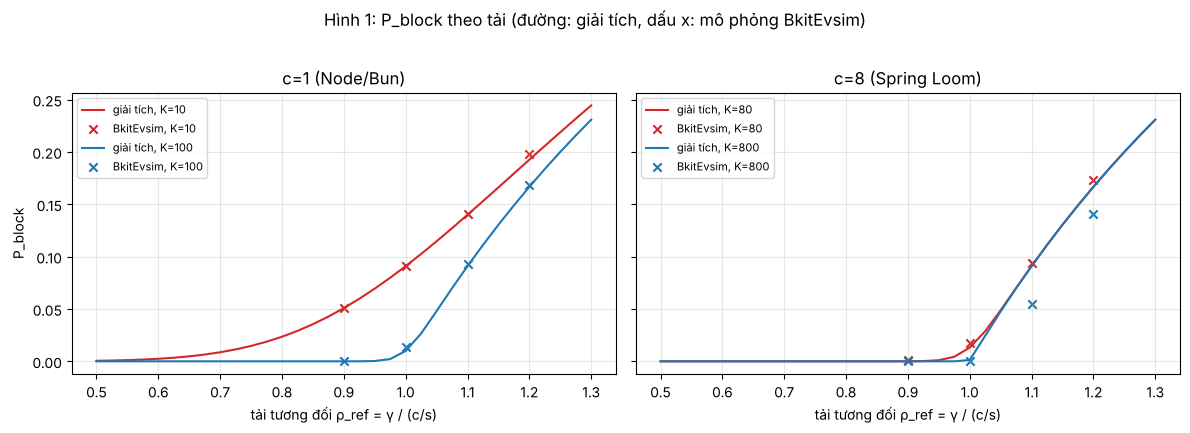

In [16]:
# Hình minh họa 1: P_block theo tải, giải tích so với mô phỏng BkitEvsim, thay K/core (c=1: Node/Bun; c=8: Loom)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
rhos = np.linspace(0.5, 1.3, 33)
for ax, c_ in zip(axes, (1, 8)):
    for kpc, col in ((10, "tab:red"), (100, "tab:blue")):
        K_ = kpc * c_
        ax.plot(rhos, [tandem_free(r * c_ / s, c_, K_, s, D)["Pblock"] for r in rhos], color=col, label=f"giải tích, K={K_}")
        pts = [(r, run_model(r * c_ / s, c_, K_, s, D, "FREE", n_req=20_000, seed=5)["Pblock"]) for r in (0.9, 1.0, 1.1, 1.2)]
        ax.scatter(*zip(*pts), color=col, marker="x", label=f"BkitEvsim, K={K_}")
    ax.set_title(f"c={c_}" + (" (Node/Bun)" if c_ == 1 else " (Spring Loom)"))
    ax.set_xlabel("tải tương đối ρ_ref = γ / (c/s)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("P_block")
fig.suptitle("Hình 1: P_block theo tải (đường: giải tích, dấu x: mô phỏng BkitEvsim)", y=1.02)
plt.tight_layout(); plt.show()

## 8. Bước 8 – Thiết kế thí nghiệm (mô tả kế hoạch)

**Mục tiêu:** thu nhiều thông tin nhất với ít công sức nhất. Không chạy tổ hợp đầy đủ mọi factor mà chia thành bảy thí nghiệm, mỗi thí nghiệm trả lời một câu hỏi ở §1.2.

| # | Thí nghiệm | Factor đổi | Giữ cố định | Trả lời |
|---|---|---|---|---|
| E1 | Quét tải tới bão hòa | `ρ_ref` ∈ {0,2; 0,4; 0,6; 0,8; 0,9; 0,95; 1,05; 1,2}; hệ ∈ {Node, Loom, Pool} | `s`=1 ms, `D`=50 ms, `K` cơ sở | hệ nào bão hòa trước (câu 1, 3) |
| E2 | Tái hiện dạng tải của sample (closed-loop) | `C` ∈ {100; 1.500; 5.000}; `K/core` ∈ {100; ∞} | `s`, `D`, `c` | tỉ lệ lỗi, Little (câu 6) |
| E3 | Độ trễ I/O và thời gian CPU | `D` ∈ {10; 50; 200 ms} × `s` ∈ {0,2; 1; 5 ms}; hệ ∈ {Node, Loom, Pool} | `ρ_ref`=0,8 | khi nào pool bão hòa; `R` tăng đúng `D` (câu 2, 5) |
| E4 | Số core và dung lượng | `c` ∈ {1; 4; 8} × `K/core` ∈ {10; 100; ∞} | `ρ_ref`=0,95 | ảnh hưởng của `c`, `K` lên `P_block` và `R` (câu 4) |
| E5 | `FREE` so với `HOLD` | `policy` × `ρ_ref` ∈ {0,7; 0,95; 1,1} | `c`=8 | khác biệt nonblocking và blocking (câu 2) |
| E6 | Validation | node đơn (6 mô hình) × 3 mức tải; tandem `FREE` | – | mô phỏng so với giải tích (§9) |
| E7 | Giai thừa 2³ | `ρ_ref` {0,7; 1,1} × `K/core` {10; 100} × `c` {1; 8} | – | tương tác giữa các yếu tố |

**Quy trình mỗi lần chạy:** khởi tạo LP, chạy `n` request, **bỏ 10% đầu** (warm-up), ghi metric ở `SinkLP`, `DispatcherLP`, `WorkerLP`, `IoLP`; mỗi cấu hình chạy với **nhiều hạt giống ngẫu nhiên cố định để tái lập**; thứ tự chạy được ngẫu nhiên hóa.

In [17]:
SEEDS, N_REQ = 10, 30_000
plan = []
LV = [0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 1.05, 1.2]
SYS3 = {"Node": ("FREE", 1), "Loom": ("FREE", 8), "Pool": ("HOLD", 8)}
def Kfor(name, kpc): return "P+200" if name == "Pool" else kpc
for name, (pol, c_) in SYS3.items():                           # E1
    for rho in LV:
        plan.append(dict(exp="E1", system=name, c=c_, policy=pol, load="open", level=rho, C=None, K_per_core=Kfor(name, 100), D=50e-3, s=1e-3))
for name, (pol, c_) in SYS3.items():                           # E2
    for C_ in (100, 1500, 5000):
        for kpc in (100, None):
            plan.append(dict(exp="E2", system=name, c=c_, policy=pol, load="closed", level=None, C=C_, K_per_core=Kfor(name, kpc), D=50e-3, s=1e-3))
for name, (pol, c_) in SYS3.items():                           # E3
    for D_ in (10e-3, 50e-3, 200e-3):
        for s_ in (0.2e-3, 1e-3, 5e-3):
            plan.append(dict(exp="E3", system=name, c=c_, policy=pol, load="open", level=0.8, C=None, K_per_core=Kfor(name, 100), D=D_, s=s_))
for c_ in (1, 4, 8):                                           # E4
    for kpc in (10, 100, None):
        plan.append(dict(exp="E4", system=f"c={c_}", c=c_, policy="FREE", load="open", level=0.95, C=None, K_per_core=kpc, D=50e-3, s=1e-3))
for pol in ("FREE", "HOLD"):                                   # E5
    for rho in (0.7, 0.95, 1.1):
        plan.append(dict(exp="E5", system="Loom", c=8, policy=pol, load="open", level=rho, C=None, K_per_core=Kfor("Pool" if pol == "HOLD" else "Loom", 100), D=50e-3, s=1e-3))
for rho in (0.7, 1.1):                                         # E7 (2^3)
    for kpc in (10, 100):
        for c_ in (1, 8):
            plan.append(dict(exp="E7", system=f"c={c_}", c=c_, policy="FREE", load="open", level=rho, C=None, K_per_core=kpc, D=50e-3, s=1e-3))
plan = pd.DataFrame(plan)

runs = plan.loc[plan.index.repeat(SEEDS)].copy()
runs["seed"] = runs.groupby(level=0).cumcount() + 1
runs = runs.reset_index(drop=True).sample(frac=1, random_state=2026).reset_index(drop=True)   # ngẫu nhiên hóa thứ tự
runs.insert(0, "run_id", range(1, len(runs) + 1))
runs["n_requests"] = N_REQ

summary = plan.groupby("exp").size().rename("số cấu hình").to_frame()
summary.loc["E6 (validation, §9)"] = 18                       # 6 mô hình × 3 mức tải
summary["số lần chạy"] = summary["số cấu hình"] * SEEDS
summary.loc["Tổng"] = summary.sum()
print(summary.to_string())
runs.head(6)

                     số cấu hình  số lần chạy
exp                                          
E1                            24          240
E2                            18          180
E3                            27          270
E4                             9           90
E5                             6           60
E7                             8           80
E6 (validation, §9)           18          180
Tổng                         110         1100


,run_id,exp,system,c,policy,load,level,C,K_per_core,D,s,seed,n_requests
0,1,E1,Pool,8,HOLD,open,0.95,NaN,P+200,0.05,0.001,9,30000
1,2,E1,Loom,8,FREE,open,1.20,NaN,100,0.05,0.001,2,30000
2,3,E3,Loom,8,FREE,open,0.80,NaN,100,0.20,0.005,4,30000
3,4,E2,Loom,8,FREE,closed,NaN,1500.0,100,0.05,0.001,6,30000
4,5,E4,c=4,4,FREE,open,0.95,NaN,100,0.05,0.001,9,30000
5,6,E5,Loom,8,FREE,open,1.10,NaN,100,0.05,0.001,10,30000


In [18]:
# Ước lượng thời gian bằng cách đo một lần chạy BkitEvsim thật
t0 = time.time(); rr = run_model(7600, 8, 800, 1e-3, 50e-3, "FREE", n_req=N_REQ, seed=1); dt = time.time() - t0
total = int(summary.loc["Tổng", "số lần chạy"])
print(f"1 lần chạy BkitEvsim ({N_REQ} request, {rr['events']} sự kiện): {dt:.1f} s  ({rr['events']/dt:,.0f} sự kiện/s)")
print(f"{total} lần chạy ≈ {total*dt/60:.0f} phút ≈ {total*dt/3600:.1f} giờ (chạy tuần tự, một máy)")

1 lần chạy BkitEvsim (30000 request, 240001 sự kiện): 4.4 s  (54,160 sự kiện/s)
1100 lần chạy ≈ 81 phút ≈ 1.4 giờ (chạy tuần tự, một máy)


**Kiểm soát sai lệch:** bỏ warm-up; nhiều hạt giống; ngẫu nhiên hóa thứ tự; chọn `bucket_width` phủ hết thời gian mô phỏng; kiểm tra Little và bảo toàn request ở mọi lần chạy; loại lần chạy vi phạm; mọi thao tác chờ dùng thời gian mô phỏng, không dùng timeout theo đồng hồ thật.

### 8.1 Kế hoạch kiểm tra mô hình

**Verification (mô hình có được xây đúng không)**

| Nhóm | Kiểm tra | Cách làm | Tiêu chí |
|---|---|---|---|
| Component testing | Từng trạm độc lập | cắt riêng một trạm, cấp tải Poisson, so với công thức: M/M/1, M/M/c, M/M/1/K, M/M/c/K, M/M/∞, M/M/c/c; mỗi trạm thử ≥ 3 mức tải (thấp, cao, quá tải với trạm hữu hạn) | giá trị lý thuyết nằm trong khoảng tin cậy 95%; sai số tương đối < 5% |
| Component testing | Tandem `FREE` | so $R=W_{\mathrm{CPU}}+D$, $L_{\mathrm{IO}}=\lambda_{\mathrm{eff}}D$, `P_block` với công thức (§6.8) | sai số < 3% |
| Logical consistency | Định luật Little | kiểm tra `L_CPU = λ_eff·W_CPU`, `L_q = λ_eff·W_q` ở trạm CPU; `L_sys = X·R` toàn hệ thống | sai số < 3%, cùng nhóm request và cùng khoảng quan sát |
| Logical consistency | Bảo toàn request | $N_0+N_{\mathrm{arrived}}=N_{\mathrm{done}}+N_{\mathrm{rejected}}+N_{\mathrm{remaining}}$; số bị từ chối = số đến khi `n_CPU = K` | hai vế bằng nhau, không thiếu hay đếm trùng |
| Logical consistency | Bất biến | số server bận ≤ `c`; số request ở trạm CPU ≤ `K` tại mọi thời điểm | không vi phạm |
| Trace analysis | Thứ tự thời gian | timestamp sự kiện không giảm; local virtual time không giảm | không vi phạm |
| Trace analysis | Tái lập | cùng seed | kết quả giống hệt |
| Trace analysis | Hai dispatcher | `sequential` và `distributed_sequential` (cần xác nhận cả hai chạy được LP coroutine; nếu không thì so ở bản LP đồng bộ) | thống kê tương đương |
| Trace analysis | Độc lập với thời gian thực | chạy khi máy tải nặng/nhẹ; mọi độ trễ là sự kiện có timestamp mô phỏng | kết quả không đổi |

**Validation (mô hình có đúng với hệ thống thật không)**

| Nhóm | Kiểm tra | Cách làm | Tiêu chí |
|---|---|---|---|
| Model accuracy | Chỉ số cả hệ | so `X`, `P_block`, `R`, `U` đo được với công thức ở 4 workload; riêng `HOLD` so với xấp xỉ M/M/P/K và nêu sai lệch | đúng xu hướng; sai lệch được giải thích |
| System testing | Hành vi hợp lý | tăng `γ` thì `R` và `P_block` tăng; thêm server thì `R` giảm; tăng `D` thì `R` tăng đúng `D` ở hệ `FREE` | đúng chiều |
| Realistic scenarios | Hành vi hệ thống thực | event loop bão hòa ở `1/s`; pool bão hòa ở `P/(s+D)`; closed-loop quá tải tạo tỉ lệ lỗi cao | khớp định tính |
| Realistic scenarios | (Tùy chọn) Số liệu thực | tự chạy `wrk` một lần cho mỗi runtime, hoặc dùng sample **sau khi** lọc response lỗi | cùng bậc độ lớn |

## 9. Bước 9 – Phân tích số liệu (mô tả kế hoạch)

**Việc sẽ làm sau khi có số liệu:**
1. **Thống kê mô tả:** với mỗi cấu hình và metric, trung bình qua các hạt giống, độ lệch chuẩn, **khoảng tin cậy 95%** (phân phối t).
2. **Kiểm tra nhất quán:** Little ở mọi lần chạy; bảo toàn request; `ρ` đo được so với `λ_eff·s/c`.
3. **Validation:** sai số tương đối giữa mô phỏng và giải tích ở tải thấp và gần bão hòa.
4. **So sánh hệ thống:** kiểm định không tham số (Mann–Whitney) hoặc t-test Welch giữa hai hệ; báo cả kích thước hiệu ứng, không chỉ p-value.
5. **Điểm bão hòa (knee):** tải mà thông lượng ngừng tăng hoặc `R` tăng đột ngột; so với `X_max` lý thuyết.
6. **Xác định nút cổ chai:** nút nào có `U` cao nhất, `P_block` tăng sớm nhất.
7. **Độ nhạy và tương tác:** xếp hạng ảnh hưởng của các factor; phân tích phương sai cho thiết kế 2³ (E7).
8. **Giải thích sai lệch:** nêu rõ vì sao công thức M/M/P/K lệch ở thread pool (thời gian phục vụ `s + D` không mũ) và coi đó là giới hạn của xấp xỉ chứ không phải lỗi mô phỏng.

In [19]:
def mean_ci(x, conf=0.95):
    x = np.asarray(x, dtype=float)
    n = len(x)
    m = x.mean()
    if n < 2:
        return m, np.nan, np.nan
    h = stats.sem(x) * stats.t.ppf((1 + conf) / 2, n - 1)
    return m, m - h, m + h

def compare_runs(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    sp = math.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return dict(mean_a=a.mean(), mean_b=b.mean(), ratio_a_over_b=a.mean() / b.mean(),
                p_value=u.pvalue, cohen_d=(a.mean() - b.mean()) / sp if sp > 0 else np.nan)

def validation_error(measured, predicted):
    measured, predicted = np.asarray(measured, float), np.asarray(predicted, float)
    return 100 * (measured - predicted) / predicted

def knee(loads, throughputs, tol=0.02):
    # Điểm bão hòa: tải đầu tiên mà thông lượng tăng thêm dưới tol so với bước trước
    for i in range(1, len(loads)):
        if throughputs[i] < throughputs[i - 1] * (1 + tol):
            return loads[i - 1]
    return loads[-1]

def little_check(L, X, R, tol=0.03):
    # Little ở một trạm hoặc toàn hệ thống: trả về (X·R, lệch tương đối, đạt?)
    dev = abs(L - X * R) / L
    return X * R, dev, dev <= tol

def conservation_check(n_start, n_arrived, n_done, n_blocked, n_remaining):
    # N_0 + N_arrived = N_done + N_rejected + N_remaining
    return (n_start + n_arrived) == (n_done + n_blocked + n_remaining)

def bottleneck(c, s, D, P=None):
    caps = {"CPU (c/s)": c / s}
    if P is not None: caps["thread pool (P/(s+D))"] = P / (s + D)
    k = min(caps, key=caps.get)
    return k, caps[k], caps

# Thử hàm bằng DỮ LIỆU GIẢ (KHÔNG phải kết quả mô phỏng)
rng = np.random.default_rng(0)
demo = rng.normal(52.5, 0.4, size=10)
print("mean, ci_low, ci_high =", [round(float(v), 2) for v in mean_ci(demo)])
print("knee (giả):", knee([100, 200, 400, 800, 1000], [100, 200, 400, 790, 800]))
_x, _d, _ok = little_check(10.0, 200.0, 0.0505)
print("Little (giả): X·R =", round(float(_x), 3), "| lệch", round(float(_d), 3), "| đạt:", bool(_ok))
print("Bảo toàn (giả):", conservation_check(5, 1000, 950, 40, 15))
for nme, cfg in [("Node.js", (1, s, D)), ("Spring Loom", (8, s, D)), ("Pool P=200", (8, s, D, 200)), ("Pool P=200, D=200ms", (8, s, 0.2, 200))]:
    k, v, _ = bottleneck(*cfg)
    print(f"  {nme:20s}: nghẽn ở {k:24s} X_max = {v:7.0f} req/s")

mean, ci_low, ci_high = [52.53, 52.31, 52.76]
knee (giả): 800
Little (giả): X·R = 10.1 | lệch 0.01 | đạt: True
Bảo toàn (giả): True
  Node.js             : nghẽn ở CPU (c/s)                X_max =    1000 req/s
  Spring Loom         : nghẽn ở CPU (c/s)                X_max =    8000 req/s
  Pool P=200          : nghẽn ở thread pool (P/(s+D))    X_max =    3922 req/s
  Pool P=200, D=200ms : nghẽn ở thread pool (P/(s+D))    X_max =     995 req/s


## 10. Bước 10 – Trình bày kết quả (mô tả kế hoạch)

**Báo cáo PDF (Phase 2) gồm:** báo cáo Phase 1 (notebook này), sơ đồ kiến trúc và sơ đồ lớp (các LP), mô tả workload, mô tả thí nghiệm, validation và đánh giá, hướng dẫn sử dụng; đóng gói `Spe-Ass-final-<GroupName>.zip` cùng file PDF.

**Biểu đồ và bảng dự kiến**

| # | Hình / bảng | Thí nghiệm | Mục đích |
|---|---|---|---|
| 1 | Thông lượng theo tải, mỗi hệ một đường, dải khoảng tin cậy | E1 | điểm bão hòa của từng hệ |
| 2 | Thời gian phản hồi (trung bình, p99) theo tải | E1 | đoạn tăng dốc gần bão hòa |
| 3 | `P_block` theo tải và `K` (mô phỏng so với giải tích) | E4, E6 | ảnh hưởng của `K`, độ chính xác mô phỏng |
| 4 | Bản đồ nhiệt `U` theo (hệ, tải) | E1, E3 | nút nào bận nhất |
| 5 | `FREE` so với `HOLD` (R và P_block) | E5 | khác biệt nonblocking và blocking |
| 6 | Thông lượng tối đa theo `D` cho `FREE` và `HOLD` | E3 | khi nào pool bão hòa |
| 7 | `P_block` theo `c` và `K` | E4 | ảnh hưởng giới hạn hàng chờ |
| 8 | `X·R` so với `C`, tỉ lệ lỗi theo `C` | E2 | Little và tái hiện tỉ lệ lỗi sample |
| 9 | Bảng audit sample (tỉ lệ lỗi, Little) | §0 | so với cách nhóm đo |
| 10 | Bảng đối chiếu mô phỏng và lý thuyết từng node | E6 | verification |

Hình dưới là **dự đoán giải tích với tham số giả định** (không phải kết quả mô phỏng), cho thấy dạng của hình 6.

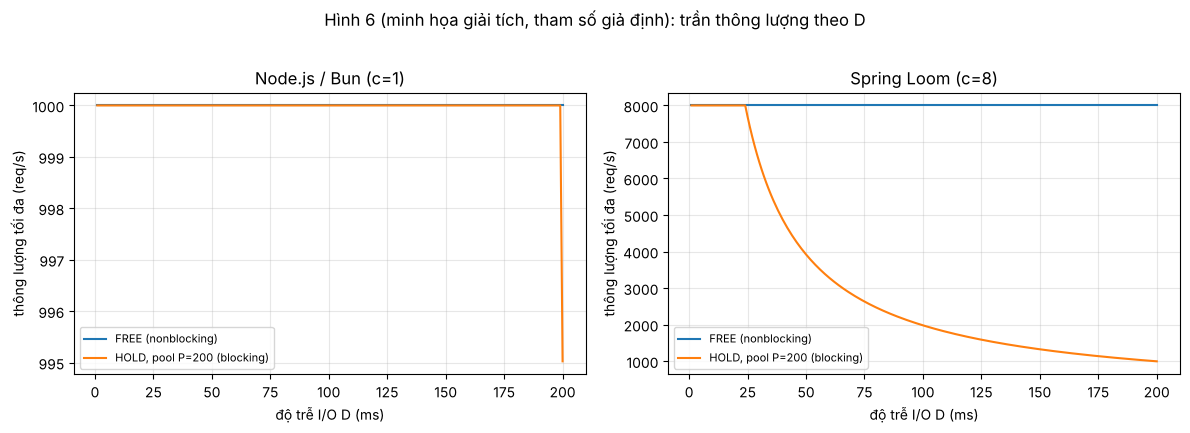

In [20]:
def max_throughput(policy, s, d, c, P=200):
    if policy == "FREE": return c / s
    if policy == "HOLD": return min(c / s, P / (s + d))
    raise ValueError(policy)

ds = np.linspace(0.001, 0.2, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (nm, c_) in zip(axes, [("Node.js / Bun (c=1)", 1), ("Spring Loom (c=8)", 8)]):
    ax.plot(ds * 1000, [max_throughput("FREE", s, d, c_) for d in ds], label="FREE (nonblocking)")
    ax.plot(ds * 1000, [max_throughput("HOLD", s, d, c_, P=200) for d in ds], label="HOLD, pool P=200 (blocking)")
    ax.set_xlabel("độ trễ I/O D (ms)"); ax.set_ylabel("thông lượng tối đa (req/s)"); ax.set_title(nm)
    ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.suptitle("Hình 6 (minh họa giải tích, tham số giả định): trần thông lượng theo D", y=1.02)
plt.tight_layout(); plt.show()

## 11. Mô tả module

### 11.1 Kiến trúc tổng thể

```
┌──────────────────────────── Configuration & Setup ────────────────────────────┐
│  Simulation Options: end_time, dispatcher, bucket_width, log_level, stats_file │
│  Tham số kịch bản: γ, c, K, s, D, policy, κ, C, warm-up, m (số lần lặp)       │
└────────────────────────────────────────────────────────────────────────────────┘
┌──────── Application Layer (user model) ────────┐   ┌───────── Core (bkitevsim) ─────────┐
│ Logical Processes (mỗi LP = 1 thành phần):     │   │ Dispatcher: sequential |           │
│  SourceLP     – sinh request ~ Exp(γ) hoặc C   │◄─►│            distributed_sequential  │
│                 kết nối (closed-loop)          │   │ Event processing: pop →            │
│  DispatcherLP – hàng chờ FIFO, giới hạn K      │   │   set_local_virt_time →            │
│  WorkerLP × c – c server của trạm CPU          │   │   handle_event → send_event        │
│  IoLP         – trạm chờ I/O: M/M/∞ (độ trễ D) │   │ Priority queue: LadderQueue        │
│  SinkLP       – thu request, đo thời gian      │   │ BkSysCoEventLoop + BkSysFuture     │
│ Mỗi LP là một coroutine, trao đổi bằng sự kiện │   │   (coroutine + giờ mô phỏng)       │
└────────────────────────────────────────────────┘   └────────────────────────────────────┘
┌──────────────────────────── Infrastructure Services ──────────────────────────┐
│  State management: trạng thái LP, danh sách server rảnh, hàng chờ              │
│  Logging & stats collector: log sự kiện, thống kê, xuất CSV                    │
└────────────────────────────────────────────────────────────────────────────────┘
```

### 11.2 Đặc tả thành phần

- **SourceLP.** Open-loop: sinh request theo Poisson tốc độ `γ`, mỗi request có mã định danh và thời điểm đến. Closed-loop: giữ `C` kết nối, kết nối gửi request kế tiếp ngay khi nhận phản hồi (kể cả phản hồi bị từ chối).
- **DispatcherLP (hàng chờ của trạm CPU).** Nhận `REQ`: nếu số request trong trạm bằng `K` thì **từ chối** (gửi `REJECT` về Sink); ngược lại giao cho worker rảnh hoặc xếp vào hàng FIFO. Nhận `IDLE` từ worker: giảm bộ đếm, giao việc kế tiếp hoặc đánh dấu worker rảnh.
- **WorkerLP × c (server).** Nhận `JOB`, phục vụ `Exp(s)` (gửi sự kiện `SERVED` cho chính mình tại `now + Exp(s)`), rồi:
  - `FREE`: nhả ngay (gửi `IDLE` về Dispatcher) và chuyển request sang `IoLP`.
  - `HOLD` (mốc so sánh): phục vụ `Exp(s) + Exp(D)` rồi mới nhả và trả lời thẳng đến Sink; số worker là `P`.
- **IoLP (trạm I/O).** Không giới hạn chỗ: với mỗi `IO_REQ`, lên lịch sự kiện `IO_FIN` cho chính nó tại `now + Exp(D)` rồi chuyển `DONE` đến Sink (không chờ từng request). Không phản hồi lên trạm CPU.
- **SinkLP.** Thu request hoàn thành và request bị từ chối, ghi thời gian phản hồi kèm lý do rời đi (`DONE`, `REJECTED`).
- **Cơ chế BkitEvsim.** Toàn bộ xử lý nằm trong `handle_event`; mọi độ trễ (CPU, I/O) là sự kiện gửi cho chính LP với timestamp ở tương lai, nên không dùng tham số `timeout` (theo đồng hồ thật) của `wait_for`. Thuật toán chi tiết ở §6.5, mã ở §6.6.

### 11.3 Luồng hoạt động

1. `SourceLP` sinh request tại thời điểm `t` và lên lịch lần đến kế tiếp sau `Exp(γ)` (open-loop).
2. Request đến `DispatcherLP`: nếu `n = K` thì bị từ chối (`REJECT` đến Sink); ngược lại giao cho worker rảnh hoặc xếp hàng.
3. `WorkerLP` phục vụ CPU `Exp(s)`, nhả server (`IDLE`) và chuyển request sang `IoLP`.
4. `IoLP` lên lịch `IO_FIN` tại `now + Exp(D)` rồi gửi `DONE` đến `SinkLP`.
5. `SinkLP` ghi thời gian phản hồi `R` (từ lúc đến đến lúc Sink nhận).
6. Mô phỏng dừng khi hết sự kiện hoặc tại `T_end`; thống kê chỉ tính sau thời gian khởi động.

### 11.4 Tổng kết

| Thành phần | Vai trò | Mô hình | Sự kiện chính |
|---|---|---|---|
| SourceLP | sinh request | Poisson(γ) / closed-loop | `REQ` |
| DispatcherLP | hàng chờ + giới hạn `K` | phần hàng chờ của M/M/c/K | `REQ`, `IDLE`, `JOB`, `REJECT` |
| WorkerLP × c | server CPU | phần phục vụ của M/M/c/K (hoặc M/G/P/K với `HOLD`) | `JOB`, `IO_REQ`, `IDLE` |
| IoLP | trạm chờ I/O | M/M/∞ | `IO_REQ`, `IO_DONE` |
| SinkLP | thu request, đo thời gian | bộ thu thống kê | `IO_DONE`, `DONE`, `REJECT` |



## 12. Checklist và việc còn mở

**Checklist Phase 1 (thiết kế)**
- [ ] Đăng link sample lên forum
- [ ] Hoàn tất audit sample: mở các file `result_*.txt` còn lại (Node cluster, Java truyền thống, dòng I/O), làm cùng phép tính ở §0.2
- [x] Bước 1–7 đã có (§1–§7); hệ thống chính là nonblocking
- [ ] Điền ô thông tin nhóm
- [x] Bước 8–10 đã mô tả kế hoạch (§8–§10) và mô tả module (§11)
- [ ] Xuất PDF `Spe-Ass-Spec-<GroupName>.pdf`

**Việc còn mở**
1. Bun được giả định là event loop một luồng (cần xác nhận); nếu khác, chỉ đổi `c` hoặc `κ` của Bun.
2. Giả thuyết ở §0.3 (tỉ lệ lỗi của sample do closed-loop kết hợp sức chứa hữu hạn) chưa kiểm chứng; kiểm chứng ở E2.
3. Thread pool dùng làm mốc blocking với `P = 200`; cần xác nhận giá trị mặc định thực tế.
4. Giấy phép framework chỉ cho dùng trong môn học, không đăng mã công khai.